# Flux: Gross primary production (GPP) (2004-2025)

# About this notebook

Overview of the gross primary production (`GPP`) of CH-LAE, 2004 to 2025, from the merged flux
record `30_FLUX_POST-PROCESSING_CHAIN/99_FPPC_MERGED_2004-2026.09`. This notebook computes and
corrects nothing; it describes what the flux chain produced.

**GPP is modelled, not measured.** Eddy covariance measures the net exchange `NEE`. The
partitioning (Level 4.2 on the documentation site) splits the gap-filled `NEE` into `GPP` and ecosystem
respiration (`RECO`). There is therefore no measured `GPP` series and no gap-filling flag of its
own. How far a period rests on measurement is given by the fill flag of the underlying `NEE`.

**Two partitioning methods.**

- *Nighttime method* (Reichstein et al. 2005). A temperature response of respiration is fitted to
  measured nighttime `NEE`, `RECO` is modelled for every half-hour, and `GPP` is `RECO` minus the
  gap-filled `NEE`. `GPP` is computed at night as well. There it scatters around zero, and it is
  negative wherever `NEE` exceeds the modelled `RECO`.
- *Daytime method* (Lasslop et al. 2010). A light response with a temperature and VPD term is
  fitted to daytime `NEE`, and `GPP` is the modelled uptake. It is zero at night and never negative.

**Sign convention and units.** `GPP` is positive: it is the gross uptake of CO2. Half-hourly values
are in µmol CO2 m⁻² s⁻¹; sums are in gC m⁻² (1 µmol m⁻² s⁻¹ over 30 minutes is 0.0216 gC m⁻²).
Daily, monthly and annual sums run over all half-hours, nighttime ones included.

**Columns used**

- `GPP_NT_OF_CUT_50` — `GPP` from the nighttime partitioning of the `NEE` filtered at the median
  USTAR threshold (`CUT_50`). **The main series of this notebook** and the one used throughout
  unless stated otherwise
- `GPP_NT_OF_CUT_16`, `GPP_NT_OF_CUT_84` — the same for the other two USTAR scenarios, for the
  USTAR uncertainty
- `GPP_NT_OF_ROB_CUT_50` — the outlier-robust variant of the nighttime method: the reference
  respiration of each window is refitted without the 5 % of nighttime records that deviate most
  from the window mean
- `GPP_DT_OF_CUT_50`, `GPP_DT_OF_CUT_16`, `GPP_DT_OF_CUT_84` — `GPP` from the daytime partitioning
- `RECO_NT_OF_CUT_50` — `RECO` of the nighttime method, used only to check that `GPP` is `RECO`
  minus `NEE`
- `NEE_L3.1_L3.3_CUT_50_QCF_gfXG`, `NEE_L3.1_L3.3_CUT_50_QCF` — the gap-filled `NEE` that is
  partitioned, and the same before gap-filling
- `FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED` — `0` measured, `1` gap-filled `NEE`
- `FLAG_FLUX_SOURCE` — the gas analyser of each half-hour: `75` LI-7500, `72` LI-7200

**Two gas analysers.** The record joins two analysers of different design. The open-path LI-7500
(`IRGA75`) measured from 2004; its CO2 flux is corrected for self-heating at Level 1.1. The
enclosed-path LI-7200 (`IRGA72`) measured from January 2016. The two ran in parallel until December
2017, and the merged record switches from the LI-7500 to the LI-7200 on 1 January 2016. *Gas
analyser phases* below lists all phases of the record, and *The two analysers in parallel* compares
them where both measured.

::: {.callout-important title="Read the analyser change before comparing years across 2016"}

A difference between the years before and after 2016 can come from the forest, from the change of
analyser, or from the partitioning. The nighttime method fits `RECO` on measured nighttime `NEE`
only. The LI-7500 misses many wet nights and reads too low on cold and humid nights, so `RECO` and,
with it, `GPP` of the nighttime method are likely biased low in 2004-2015. See *Issues* and
*Comparisons of the LI-7500 years* on the documentation site, and the sections on the parallel
period and on the two methods below.

:::

**Conventions used throughout**

- *Sums, not means.* Annual and monthly values are sums in gC m⁻². The measured share of the
  underlying `NEE` is reported before any statistic.
- *Uncertainty.* The USTAR part is half the difference between the `CUT_84` and `CUT_16` sums. The
  difference between the nighttime and the daytime method is a second, independent spread. No
  random uncertainty is propagated for `GPP`.
- *Half-hours with measured NEE* are used where the point is the measurement itself: the light
  response and the comparison of the two analysers.

**Timestamps.** The record is stored on `TIMESTAMP_MIDDLE` at 30 minutes in CET (UTC+1), so a
record labelled `13:15` is the average over `13:00` to `13:30`.

</br>

# Settings

In [1]:
# Columns of the merged flux record (30_FLUX_POST-PROCESSING_CHAIN/99).
varname = 'GPP_NT_OF_CUT_50'  # the main series, used unless stated otherwise
varname_dt = 'GPP_DT_OF_CUT_50'  # daytime method, for comparison
varname_rob = 'GPP_NT_OF_ROB_CUT_50'  # outlier-robust nighttime method, for comparison
SCENARIOS = {'CUT_16': 'GPP_NT_OF_CUT_16', 'CUT_50': 'GPP_NT_OF_CUT_50', 'CUT_84': 'GPP_NT_OF_CUT_84'}
SCENARIOS_DT = {'CUT_16': 'GPP_DT_OF_CUT_16', 'CUT_50': 'GPP_DT_OF_CUT_50', 'CUT_84': 'GPP_DT_OF_CUT_84'}
reco_nt = 'RECO_NT_OF_CUT_50'  # only for the check GPP = RECO - NEE
nee = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'  # the gap-filled NEE that is partitioned
nee_measured = 'NEE_L3.1_L3.3_CUT_50_QCF'  # the same before gap-filling
flagname = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'  # fill flag of the underlying NEE
sourcename = 'FLAG_FLUX_SOURCE'
SOURCE_LEGEND = {75: 'LI-7500 (open path, IRGA75)', 72: 'LI-7200 (enclosed path, IRGA72)'}
# Measured drivers in the same file, for the light response.
SW_IN = 'SW_IN_T1_47_1_MEASURED'
DAYTIME, NIGHTTIME = 'DAYTIME', 'NIGHTTIME'

var = "GPP"  # name shown in plots
units = "µmol m-2 s-1"
units_sum = "gC m-2"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2

# Period covered by the yearly statistics: the full years of the record. The record runs to
# 30 September 2026; 2026 is incomplete and appears only in the phase overview.
FIRST_YEAR = 2004
LAST_YEAR = 2025
# The daytime method needs measured shortwave radiation, which is missing in 2004
# (docs/L4.2.md, docs/Issues.md). Its first year:
DT_FIRST_YEAR = 2005

# The phases of the record, as they enter the merged product. Dates are the first day of each phase
# (TIMESTAMP_MIDDLE); a phase ends where the next one begins. Sources: docs/Instrumentation.md,
# docs/L1.md and the setup table in docs/Yearly_Notes.md.
PHASES = [
    ('2004-01-01', 'LI-7500 only', 75,
     'open-path LI-7500; CO2 flux corrected for self-heating (Level 1.1)'),
    ('2016-01-01', 'LI-7200, LI-7500 in parallel', 72,
     'LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still '
     'measures and is compared below, but is not used in the product'),
    ('2017-12-13', 'LI-7200, first unit', 72,
     'LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018'),
    ('2019-01-10', 'no LI-7200 flux', 72,
     'both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); '
     'the whole phase is gap-filled'),
    ('2019-03-20', 'LI-7200, second unit', 72,
     'second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted'),
    ('2023-03-13', 'LI-7200, inlet moved', 72,
     'analyser moved on the boom, which changed its separation from the sonic anemometer'),
    ('2025-12-02', 'LI-7200, recalibrated unit', 72,
     'a freshly calibrated LI-7200 installed'),
]
RECORD_END = '2026-09-30 23:45'

# The two analysers ran in parallel from the start of the LI-7200 to the removal of the LI-7500.
PARALLEL = ('2016-01-11', '2017-12-12')

# Analysis parameters.
N_RECENT_YEARS = 10  # length of the recent period in the period sums
N_EXTREMES = 10  # number of days listed in the extremes tables
REFERENCE_START_YEAR = FIRST_YEAR  # reference period for all anomalies
REFERENCE_END_YEAR = LAST_YEAR
GS_SMOOTHING_DAYS = 15  # running mean of daily GPP that defines the growing season
GS_FRACTION = 0.2  # growing season: smoothed daily GPP above this fraction of the year's peak
LIGHT_MONTHS = [6, 7, 8]  # full canopy, for the light response
LIMITS = (-60.0, 60.0)  # physical limits for the integrity check, umol m-2 s-1

# Input files. Data files live in the external (untracked) data folder, mirroring this repo.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\30_FLUX_POST-PROCESSING_CHAIN")
FILENAME = "99_FPPC_MERGED_2004-2026.09.parquet"
# The per-analyser records, for the parallel period only.
FILE_IRGA75 = r"IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet"
FILE_IRGA72 = r"IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet"
# Only the columns used here are read, which keeps the memory use small.
COLUMNS = [*SCENARIOS.values(), varname_rob, *SCENARIOS_DT.values(), reco_nt, nee, nee_measured,
           flagname, sourcename, SW_IN, DAYTIME, NIGHTTIME]

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import kendalltau, theilslopes

import diive as dv
from diive.core.plotting.cumulative import CumulativeYear
from diive.core.plotting.bar import LongtermAnomaliesYear

NOTEBOOK_START = datetime.now()
warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def per_year(s, how='mean'):
    """Aggregate `s` to one value per year, indexed by the year number instead of by a timestamp."""
    out = s.resample('YE').agg(how)
    out.index = out.index.year
    out.index.name = 'YEAR'
    return out


def per_year_month(s, how='mean', month_names=True):
    """Aggregate `s` to a table of YEAR (rows) by MONTH (columns)."""
    out = s.groupby([s.index.year, s.index.month]).agg(how).unstack()
    out.index.name = 'YEAR'
    if month_names:
        out.columns = [calendar.month_abbr[m] for m in out.columns]
    return out


def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure drawn with a layout engine makes room for a caption by itself. The figures pandas and
    diive build have no engine, and a caption placed in them lands on top of the tick labels. For
    those the figure is extended downwards by the height of the caption and every axes is moved up
    by the same amount, so the drawing keeps its size and position and the caption gets a free
    strip below it. `width` is the widest the caption may wrap, narrowed for a narrow figure.
    """
    # A fixed wrap width runs off the side of a narrow figure, so it is capped by how many
    # characters of this font size fit across the figure.
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure — {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12  # inches, one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)  # the old figure as a fraction of the new one
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


def window(tsmid):
    """The averaging window of a 30MIN record stored on TIMESTAMP_MIDDLE, as text."""
    start = tsmid - pd.Timedelta('15min')
    end = tsmid + pd.Timedelta('15min')
    return f"{start:%d %b %Y}, {start:%H:%M} to {end:%H:%M}"


def styled(data, caption, fmt="{:.1f}", subset=None, cmap="RdYlBu_r", axis=0, center=False):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table, so it is written as a sentence about what the table
    shows rather than as a title. `center` puts the midpoint of the colour scale at zero, and
    `axis=None` scales the colours across the whole table instead of column by column. The colour
    scale sets a text colour per cell, so the numbers stay readable in both the light and the dark
    version of the rendered page.
    """
    # Formats apply to numbers only, so text columns are dropped from the map. Without this a
    # table carrying a date or a label raises at render time, not at call time.
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        values = data[subset] if subset is not None else data
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def trend(yearly):
    """Theil-Sen slope per decade of a yearly series, with its 95 % interval and Kendall's tau.

    Theil-Sen rather than least squares because a single extreme year does not move it, and
    Kendall's tau because it tests a monotonic trend without assuming normal residuals.
    """
    years = yearly.index.to_numpy(dtype=float)
    values = yearly.to_numpy(dtype=float)
    slope, intercept, low, high = theilslopes(values, years, alpha=0.95)
    tau, pvalue = kendalltau(years, values)
    return dict(slope=slope * 10, low=low * 10, high=high * 10, tau=tau, pvalue=pvalue,
                fit=pd.Series(intercept + slope * years, index=yearly.index))


def longest_spell(mask):
    """Length in days and start date of the longest run of True in a daily boolean series."""
    blocks = mask.ne(mask.shift()).cumsum()
    runs = mask[mask].groupby(blocks[mask]).size()
    if runs.empty:
        return 0, pd.NaT
    return int(runs.max()), mask.index[blocks == runs.idxmax()][0]


def year_axis(ax):
    """Integer year ticks. Matplotlib otherwise labels a numeric year axis with half-years."""
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    return ax


def to_gc(s):
    """Half-hourly GPP in umol m-2 s-1 summed to gC m-2 over whatever period `s` covers.

    `min_count=1` keeps a period without any value (the daytime method in 2004) empty instead of
    turning it into a sum of zero.
    """
    return s.sum(min_count=1) * UMOL_TO_GC


def phase_of(index):
    """The phase name of each timestamp in `index`."""
    starts = pd.to_datetime([p[0] for p in PHASES])
    pos = np.searchsorted(starts.to_numpy(), index.to_numpy(), side='right') - 1
    return pd.Series([PHASES[i][1] for i in pos], index=index)


def shade_phases(ax, alpha=0.08):
    """Shade the analyser phases behind a time axis and mark their boundaries."""
    colors = ['#1E88E5', '#43A047', '#FB8C00', '#9E9E9E', '#8E24AA', '#00ACC1', '#E53935']
    bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END)]
    for i, (start, end) in enumerate(zip(bounds[:-1], bounds[1:])):
        ax.axvspan(start, end, color=colors[i % len(colors)], alpha=alpha, lw=0)
        ax.axvline(start, color='#616161', lw=0.6, ls=':')


def era(year):
    """The gas analyser of a calendar year in the merged record."""
    return 'LI-7500' if year < 2016 else 'LI-7200'


ERA_COLORS = {'LI-7500': '#1E88E5', 'LI-7200': '#43A047'}

</br>

# Load data

In [4]:
df_full = pd.read_parquet(Path(DATADIR) / FILENAME, columns=COLUMNS)
# Setting the frequency fails unless the index is one regular 30MIN grid.
df_full.index.freq = '30min'
print(f"Columns: {df_full.shape[1]} of the merged record")
print(f"Range:   {df_full.index[0]} -> {df_full.index[-1]} ({len(df_full):,} records)")

# The yearly statistics cover FIRST_YEAR to LAST_YEAR; the phase overview uses the full record.
df = df_full.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
series = df[varname].copy()
series_dt = df[varname_dt].copy()
nee_is_measured = df[flagname].eq(0)
is_day = df[DAYTIME].eq(1)
xlabel = f"{var} ({units})"
print(f"Kept {FIRST_YEAR}-{LAST_YEAR}: {len(df):,} records")

Columns: 15 of the merged record
Range:   2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (398,832 records)
Kept 2004-2025: 385,728 records


## Integrity checks

In [5]:
# The overview describes the record, so it starts by checking what everything below assumes: one
# continuous 30MIN record without duplicates, a complete nighttime GPP within physical limits that
# equals RECO minus NEE, a daytime GPP that is missing only before DT_FIRST_YEAR and never
# negative, complete years, and the analyser codes where the merge put them.
_issues = []
if df_full.index.duplicated().any():
    _issues.append("duplicate timestamps")
if not (df_full.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
    _issues.append("index gaps")
for _c in [*SCENARIOS.values(), varname_rob, reco_nt, nee]:
    if df[_c].isna().any():
        _issues.append(f"{_c}: {int(df[_c].isna().sum())} missing values")
for _c in SCENARIOS_DT.values():
    _miss_years = sorted(set(df.index[df[_c].isna()].year))
    if _miss_years != list(range(FIRST_YEAR, DT_FIRST_YEAR)):
        _issues.append(f"{_c}: missing values in {_miss_years}")
    if (df[_c] < 0).any():
        _issues.append(f"{_c}: negative values")
if ((series < LIMITS[0]) | (series > LIMITS[1])).any():
    _issues.append(f"values outside {LIMITS}")
# The nighttime method defines GPP as modelled RECO minus gap-filled NEE.
_resid = (df[reco_nt] - df[nee] - series).abs().max()
if _resid > 1e-3:
    _issues.append(f"GPP_NT is not RECO_NT minus NEE (max deviation {_resid:.4f})")
_counts = series.groupby(series.index.year).size()
_short = {y: int(n) for y, n in _counts.items() if n != (17568 if calendar.isleap(y) else 17520)}
if _short:
    _issues.append(f"incomplete years: {_short}")
if set(df[flagname].unique()) - {0, 1}:
    _issues.append(f"unknown fill flags: {sorted(set(df[flagname].unique()))}")
if not (df[nee_measured].notna() == nee_is_measured).all():
    _issues.append("fill flag and measured NEE records disagree")
if not ((df_full[sourcename] == 75) == (df_full.index < '2016-01-01')).all():
    _issues.append("analyser codes not where the merge put them")

print(f"records: {len(df):,}   years: {FIRST_YEAR}-{LAST_YEAR}")
print(f"range:   {series.min():.1f} to {series.max():.1f} {units} (nighttime method), "
      f"{series_dt.min():.1f} to {series_dt.max():.1f} {units} (daytime method)")
print(f"largest deviation of GPP_NT from RECO_NT - NEE: {_resid:.2e} {units}")
assert not _issues, "the record is not what this overview assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

records: 385,728   years: 2004-2025
range:   -48.5 to 56.8 µmol m-2 s-1 (nighttime method), 0.0 to 53.8 µmol m-2 s-1 (daytime method)
largest deviation of GPP_NT from RECO_NT - NEE: 3.80e-06 µmol m-2 s-1
Integrity checks passed.


## Derived series

In [6]:
# Daily sums of the main series and of its comparisons, with the measured share of the underlying
# NEE, derived once. `daily` holds gC m-2 per day.
daily = pd.DataFrame({
    'GPP_NT': series.resample('D').sum() * UMOL_TO_GC,
    'GPP_DT': series_dt.resample('D').sum(min_count=1) * UMOL_TO_GC,
    'GPP_NT_ROB': df[varname_rob].resample('D').sum() * UMOL_TO_GC,
    'NEE': df[nee].resample('D').sum() * UMOL_TO_GC,
    'NEE measured (%)': nee_is_measured.resample('D').mean() * 100,
    'NEE measured, day (%)': nee_is_measured.where(is_day).astype(float).resample('D').mean() * 100,
})
print(f"Half-hours with measured NEE: {nee_is_measured.sum():,} of {len(series):,} "
      f"({nee_is_measured.mean() * 100:.1f} %)")
daily.describe().round(2)

Half-hours with measured NEE: 160,073 of 385,728 (41.5 %)


,GPP_NT,GPP_DT,GPP_NT_ROB,NEE,NEE measured (%),"NEE measured, day (%)"
count,8036.00,7670.00,8036.00,8036.00,8036.00,8036.00
mean,4.15,4.25,3.97,-0.37,41.50,49.06
std,4.16,4.09,4.12,3.29,25.06,28.89
min,-8.99,0.00,-9.00,-10.40,0.00,0.00
25%,0.68,0.62,0.52,-2.89,22.92,26.67
50%,3.49,2.78,3.28,0.04,41.67,53.33
75%,7.47,7.46,7.29,2.21,60.42,72.00
max,16.30,20.95,16.79,13.32,100.00,100.00


</br>

# Gas analyser phases

The record has seven phases. The analyser changed once, on 1 January 2016; the later phases are
changes within the LI-7200 record: a different unit, a gap, a moved inlet, a recalibrated unit.
`GPP` itself has no gaps; the measured share of the underlying `NEE` shows how much of each phase
the partitioning could fit on.

## 📋 Table: the phases of the record

In [7]:
_bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END) + pd.Timedelta('15min')]
_rows = []
for (start, name, code_, note), end in zip(PHASES, _bounds[1:]):
    _sel = df_full.loc[start:end - pd.Timedelta('30min')]
    _meas = _sel[flagname].eq(0)
    _rows.append({
        'phase': name, 'from': f"{pd.Timestamp(start):%d %b %Y}",
        'to': f"{end - pd.Timedelta('1D'):%d %b %Y}",
        'days': (end - pd.Timestamp(start)).days, 'analyser in the product': SOURCE_LEGEND[code_],
        f"mean daily GPP, NT ({units_sum} d-1)": _sel[varname].mean() * 48 * UMOL_TO_GC,
        'NEE measured (%)': 100 * _meas.mean(),
        'NEE measured, day (%)': 100 * _meas[_sel[DAYTIME] == 1].mean(),
        'NEE measured, night (%)': 100 * _meas[_sel[NIGHTTIME] == 1].mean(),
        'what changed': note})
phases = pd.DataFrame(_rows).set_index('phase')
display(styled(phases, caption="the phases of the record with the analyser the merged product uses in "
                               "each, the mean daily GPP of the nighttime method, and the share of "
                               "measured NEE half-hours by day and by night. Phases cover different "
                               "parts of the year, so their mean daily GPP is not comparable "
                               "between phases",
               fmt={'days': "{:.0f}", f"mean daily GPP, NT ({units_sum} d-1)": "{:.2f}",
                    'NEE measured (%)': "{:.1f}", 'NEE measured, day (%)': "{:.1f}",
                    'NEE measured, night (%)': "{:.1f}"},
               subset=['NEE measured (%)', 'NEE measured, day (%)', 'NEE measured, night (%)'],
               cmap='Blues'))

Table — the phases of the record with the analyser the merged product uses in each, the mean daily
GPP of the nighttime method, and the share of measured NEE half-hours by day and by night. Phases
cover different parts of the year, so their mean daily GPP is not comparable between phases



,from,to,days,analyser in the product,"mean daily GPP, NT (gC m-2 d-1)",NEE measured (%),"NEE measured, day (%)","NEE measured, night (%)",what changed
phase,,,,,,,,,
LI-7500 only,01 Jan 2004,31 Dec 2015,4383,"LI-7500 (open path, IRGA75)",4.04,37.9,47.6,28.2,open-path LI-7500; CO2 flux corrected for self-heating (Level 1.1)
"LI-7200, LI-7500 in parallel",01 Jan 2016,12 Dec 2017,712,"LI-7200 (enclosed path, IRGA72)",4.67,42.8,50.6,34.8,"LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still measures and is compared below, but is not used in the product"
"LI-7200, first unit",13 Dec 2017,09 Jan 2019,393,"LI-7200 (enclosed path, IRGA72)",3.63,43.2,51.6,35.1,LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018
no LI-7200 flux,10 Jan 2019,19 Mar 2019,69,"LI-7200 (enclosed path, IRGA72)",-0.23,0.0,0.0,0.0,"both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); the whole phase is gap-filled"
"LI-7200, second unit",20 Mar 2019,12 Mar 2023,1454,"LI-7200 (enclosed path, IRGA72)",4.20,47.0,56.6,37.4,second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted
"LI-7200, inlet moved",13 Mar 2023,01 Dec 2025,995,"LI-7200 (enclosed path, IRGA72)",4.83,51.0,59.4,42.3,"analyser moved on the boom, which changed its separation from the sonic anemometer"
"LI-7200, recalibrated unit",02 Dec 2025,30 Sep 2026,303,"LI-7200 (enclosed path, IRGA72)",4.22,47.7,58.6,36.0,a freshly calibrated LI-7200 installed


## 📊 Plot: the record and its phases

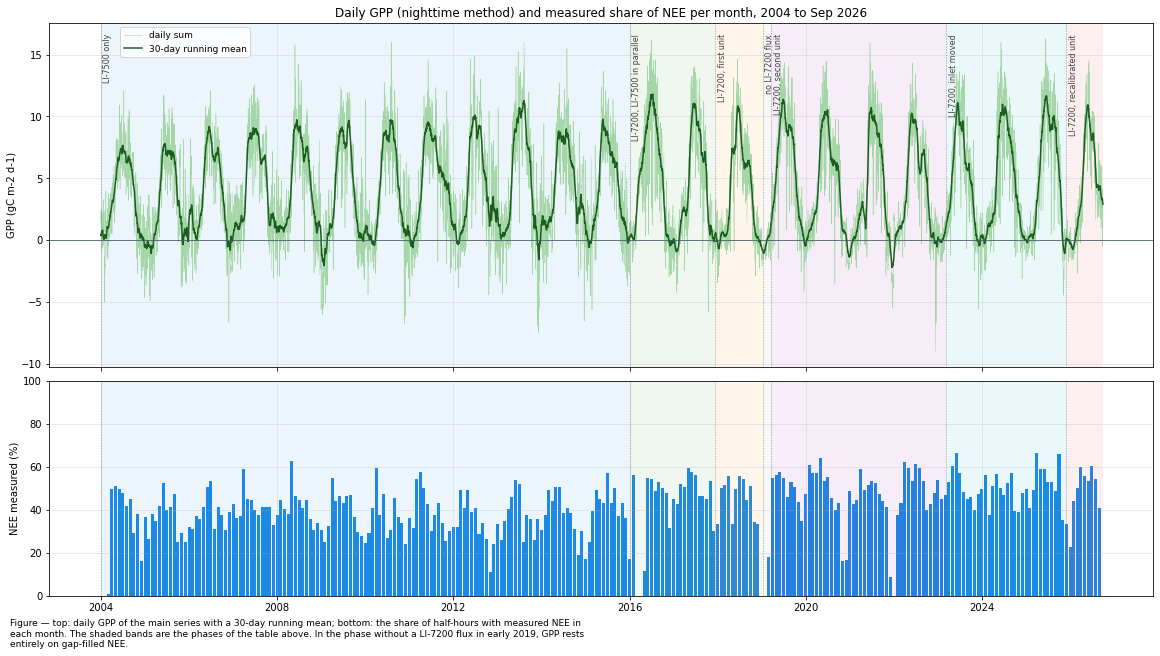

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(16, 9), dpi=72, sharex=True, layout="constrained",
                        height_ratios=[1.6, 1])
_d = df_full[varname].resample('D').sum() * UMOL_TO_GC
axs[0].plot(_d.index, _d, color='#A5D6A7', lw=0.5, label="daily sum")
axs[0].plot(_d.index, _d.rolling(30, center=True, min_periods=15).mean(), color='#1B5E20', lw=1.5,
            label="30-day running mean")
axs[0].axhline(0, color='#455A64', lw=0.8)
axs[0].set_ylabel(f"GPP ({units_sum} d-1)")
_m = df_full[flagname].eq(0).resample('MS').mean() * 100
axs[1].bar(_m.index, _m, width=25, color='#1E88E5')
axs[1].set_ylabel("NEE measured (%)")
axs[1].set_ylim(0, 100)
for _ax in axs:
    shade_phases(_ax)
    _ax.grid(alpha=0.3)
_ymax = axs[0].get_ylim()[1]
for start, name, _, _ in PHASES:
    axs[0].text(pd.Timestamp(start) + pd.Timedelta('20D'), _ymax * 0.95, name, rotation=90,
                va='top', ha='left', fontsize=8, color='#424242')
axs[0].legend(loc='upper left', fontsize=9, bbox_to_anchor=(0.06, 1))
axs[0].set_title(f"Daily GPP (nighttime method) and measured share of NEE per month, "
                 f"{df_full.index[0]:%Y} to {df_full.index[-1]:%b %Y}")
figcap(fig, "top: daily GPP of the main series with a 30-day running mean; bottom: the share of "
            "half-hours with measured NEE in each month. The shaded bands are the phases of the table "
            "above. In the phase without a LI-7200 flux in early 2019, GPP rests entirely on "
            "gap-filled NEE.")
fig.show()

## 📋 Table: half-hours per analyser and year

In [9]:
_src = df_full[sourcename].groupby(df_full.index.year).value_counts().unstack(fill_value=0)
_src.columns = [SOURCE_LEGEND[c] for c in _src.columns]
_src.index.name = 'YEAR'
display(styled(_src, caption="half-hours per year by the analyser the merged record takes them from",
               fmt="{:.0f}", cmap=None))

Table — half-hours per year by the analyser the merged record takes them from



,"LI-7500 (open path, IRGA75)","LI-7200 (enclosed path, IRGA72)"
YEAR,,
2004,17568,0
2005,17520,0
2006,17520,0
2007,17520,0
2008,17568,0
2009,17520,0
2010,17520,0
2011,17520,0
2012,17568,0


</br>

# Coverage of the underlying NEE

`GPP` is complete by construction, but it is only as good as the `NEE` it is partitioned from. This
section gives how much of that `NEE` was measured. The daytime share matters most for `GPP`, since
the uptake happens by day; the nighttime share is what the nighttime method fits respiration on.

## 📋 Table: coverage per year

In [10]:
coverage = pd.DataFrame({
    'analyser': [era(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'NEE measured (%)': per_year(nee_is_measured.astype(float), 'mean') * 100,
    'NEE measured, day (%)': per_year(nee_is_measured.where(is_day).astype(float), 'mean') * 100,
    'NEE measured, night (%)': per_year(nee_is_measured.where(~is_day).astype(float), 'mean') * 100,
    f"GPP on measured NEE (%)": (per_year(series.where(nee_is_measured & is_day), 'sum')
                                 / per_year(series.where(is_day), 'sum') * 100),
}, index=range(FIRST_YEAR, LAST_YEAR + 1))
_filled = df[flagname].eq(1)
_blocks = _filled.ne(_filled.shift()).cumsum()[_filled]
_lengths = _filled[_filled].groupby(_blocks).size() / 48
_years = df.index[_filled].to_series().groupby(_blocks.to_numpy()).first().dt.year
coverage['longest NEE gap (d)'] = pd.Series(_lengths.to_numpy(), index=_years.to_numpy()).groupby(level=0).max()
coverage.index.name = 'YEAR'
display(styled(coverage, caption="measured share of the underlying NEE per year, by day and by night, the "
                                 "share of the daytime GPP sum that falls on half-hours with measured "
                                 "NEE, and the longest gap-filled run of NEE",
               fmt={c: "{:.1f}" for c in coverage.columns},
               subset=['NEE measured (%)', 'NEE measured, day (%)', 'NEE measured, night (%)',
                       'GPP on measured NEE (%)'], cmap='Blues'))

Table — measured share of the underlying NEE per year, by day and by night, the share of the daytime
GPP sum that falls on half-hours with measured NEE, and the longest gap-filled run of NEE



,analyser,NEE measured (%),"NEE measured, day (%)","NEE measured, night (%)",GPP on measured NEE (%),longest NEE gap (d)
YEAR,,,,,,
2004,LI-7500,30.8,40.5,21.2,61.8,90.5
2005,LI-7500,36.6,46.8,26.4,62.9,3.5
2006,LI-7500,38.5,47.3,29.8,59.7,2.9
2007,LI-7500,41.7,51.1,32.3,65.9,3.3
2008,LI-7500,41.7,51.4,32.1,67.8,2.8
2009,LI-7500,38.8,49.3,28.4,70.4,2.9
2010,LI-7500,36.4,45.3,27.6,60.2,8.7
2011,LI-7500,39.5,49.7,29.4,61.4,15.0
2012,LI-7500,34.0,43.6,24.6,56.4,21.9


## 📊 Plot: measured share of daytime NEE per year and month

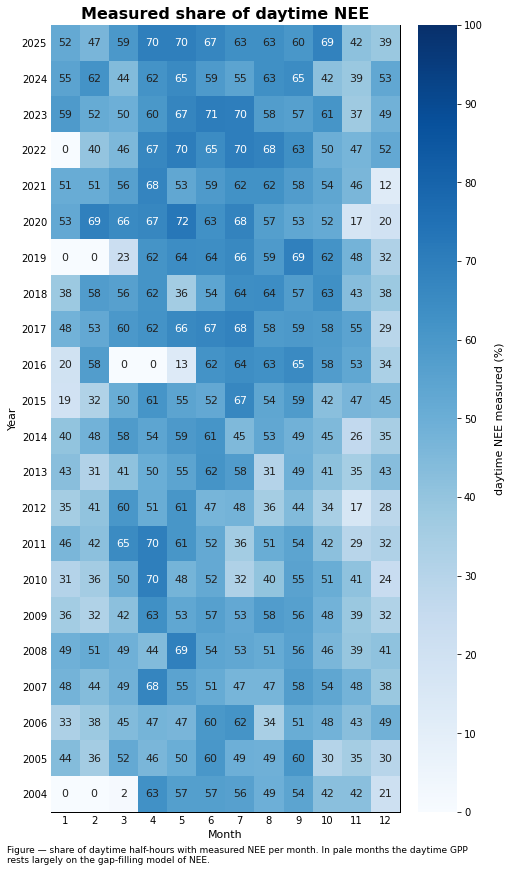

In [11]:
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
_meas_pct = (nee_is_measured.where(is_day).astype(float) * 100).rename("measured (%)")
dv.plotting.HeatmapYearMonth(series=_meas_pct, agg='mean').plot(
    ax=ax, cmap="Blues", vmin=0, vmax=100, zlabel="daytime NEE measured (%)", show_values=True,
    cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="Measured share of daytime NEE", axlabel_fontsize=11,
                                         ticks_fontsize=10))
figcap(fig, "share of daytime half-hours with measured NEE per month. In pale months the daytime GPP "
            "rests largely on the gap-filling model of NEE.")

</br>

# Negative values

`GPP` of the nighttime method is `RECO` minus `NEE` at every half-hour, so it carries the noise of
the measured `NEE` and the error of the respiration model. At night the true `GPP` is zero, and the
nighttime values scatter around it. A negative value by day means that the measured or gap-filled
`NEE` lies above the modelled `RECO`. The daytime method returns no negative values. Negative
half-hours are kept in the product and enter every sum.

## 📋 Table: share of negative GPP per year

In [12]:
_neg = series < 0
negative = pd.DataFrame({
    'analyser': [era(y) for y in range(FIRST_YEAR, LAST_YEAR + 1)],
    'negative, all (%)': per_year(_neg.astype(float), 'mean') * 100,
    'negative, day (%)': per_year(_neg.where(is_day).astype(float), 'mean') * 100,
    'negative, night (%)': per_year(_neg.where(~is_day).astype(float), 'mean') * 100,
    f"sum of negative half-hours ({units_sum})": per_year(series.where(_neg, 0), to_gc),
    f"nighttime GPP sum ({units_sum})": per_year(series.where(~is_day, 0), to_gc),
    'days with negative daily GPP': per_year(daily['GPP_NT'].lt(0).astype(float), 'sum'),
}, index=range(FIRST_YEAR, LAST_YEAR + 1))
negative.index.name = 'YEAR'
_tot = negative[f"sum of negative half-hours ({units_sum})"].sum() / len(negative)
display(styled(negative, caption=f"share of negative half-hourly GPP (nighttime method) per year, by day "
                                 f"and by night; the sum of the negative half-hours; the sum of GPP over "
                                 f"all nighttime half-hours, which would be zero without noise; and the "
                                 f"number of days whose GPP sum is negative",
               fmt={'negative, all (%)': "{:.1f}", 'negative, day (%)': "{:.1f}",
                    'negative, night (%)': "{:.1f}", f"sum of negative half-hours ({units_sum})": "{:.0f}",
                    f"nighttime GPP sum ({units_sum})": "{:+.0f}", 'days with negative daily GPP': "{:.0f}"},
               subset=['negative, all (%)', 'negative, day (%)', 'negative, night (%)'], cmap='Oranges'))
print(f"All years: {_neg.mean() * 100:.1f} % of half-hours negative "
      f"({_neg[is_day].mean() * 100:.1f} % by day, {_neg[~is_day].mean() * 100:.1f} % by night); "
      f"the negative half-hours sum to {_tot:.0f} {units_sum} per year on average.")

Table — share of negative half-hourly GPP (nighttime method) per year, by day and by night; the sum
of the negative half-hours; the sum of GPP over all nighttime half-hours, which would be zero
without noise; and the number of days whose GPP sum is negative



,analyser,"negative, all (%)","negative, day (%)","negative, night (%)",sum of negative half-hours (gC m-2),nighttime GPP sum (gC m-2),days with negative daily GPP
YEAR,,,,,,,
2004,LI-7500,28.7,18.3,39.1,-248,+54,57
2005,LI-7500,38.6,23.4,53.6,-386,-22,93
2006,LI-7500,31.5,18.9,44.0,-320,+88,59
2007,LI-7500,29.3,14.6,43.8,-292,+81,41
2008,LI-7500,27.2,16.0,38.2,-294,+98,38
2009,LI-7500,38.2,24.6,51.7,-376,+9,77
2010,LI-7500,32.6,20.9,44.1,-314,+84,61
2011,LI-7500,32.2,16.9,47.4,-312,+80,40
2012,LI-7500,35.0,18.9,50.9,-320,+42,65


All years: 33.6 % of half-hours negative (18.7 % by day, 48.3 % by night); the negative half-hours sum to -307 gC m-2 per year on average.


</br>

# Annual sums

## 📋 Table: annual sums and their spread

In [13]:
# Annual sums of the main series with the USTAR spread, the robust variant and the daytime method.
# The USTAR term is half the difference between the CUT_84 and CUT_16 sums.
yt = per_year(series, to_gc)
_scen = pd.DataFrame({k: per_year(df[c], to_gc) for k, c in SCENARIOS.items()})
_scen_dt = pd.DataFrame({k: per_year(df[c], to_gc) for k, c in SCENARIOS_DT.items()})
annual = pd.DataFrame({
    'analyser': [era(y) for y in yt.index],
    f"GPP NT ({units_sum})": yt,
    "USTAR unc. (NT)": (_scen['CUT_84'] - _scen['CUT_16']).abs() / 2,
    "NT CUT_16": _scen['CUT_16'],
    "NT CUT_84": _scen['CUT_84'],
    "NT robust": per_year(df[varname_rob], to_gc),
    "GPP DT": _scen_dt['CUT_50'],
    "USTAR unc. (DT)": (_scen_dt['CUT_84'] - _scen_dt['CUT_16']).abs() / 2,
    "NT minus DT": yt - _scen_dt['CUT_50'],
    "NT robust minus NT": per_year(df[varname_rob], to_gc) - yt,
    "NEE measured (%)": coverage['NEE measured (%)'],
})
annual["rank (most GPP first)"] = annual[f"GPP NT ({units_sum})"].rank(ascending=False).astype(int)
annual.index.name = 'YEAR'
_fmt = {c: "{:.0f}" for c in annual.columns}
_fmt.update({"NEE measured (%)": "{:.1f}", "NT minus DT": "{:+.0f}", "NT robust minus NT": "{:+.0f}"})
display(styled(annual, caption=f"annual GPP sums in {units_sum}: the nighttime method (NT, CUT_50) with its "
                               f"USTAR uncertainty and the sums of the other two USTAR scenarios; the "
                               f"outlier-robust nighttime variant; the daytime method (DT, CUT_50) with "
                               f"its USTAR uncertainty; and the differences between the methods. The "
                               f"daytime method has no result for {FIRST_YEAR}, when no shortwave "
                               f"radiation was measured",
               fmt=_fmt, subset=[f"GPP NT ({units_sum})"], cmap='Greens'))

Table — annual GPP sums in gC m-2: the nighttime method (NT, CUT_50) with its USTAR uncertainty and
the sums of the other two USTAR scenarios; the outlier-robust nighttime variant; the daytime method
(DT, CUT_50) with its USTAR uncertainty; and the differences between the methods. The daytime method
has no result for 2004, when no shortwave radiation was measured



,analyser,GPP NT (gC m-2),USTAR unc. (NT),NT CUT_16,NT CUT_84,NT robust,GPP DT,USTAR unc. (DT),NT minus DT,NT robust minus NT,NEE measured (%),rank (most GPP first)
YEAR,,,,,,,,,,,,
2004,LI-7500,1270,6,1247,1260,1205,-,-,-,-65,30.8,21
2005,LI-7500,1094,31,1054,1116,1009,1786,25,-692,-85,36.6,22
2006,LI-7500,1364,60,1305,1424,1350,1116,100,+248,-14,38.5,18
2007,LI-7500,1633,52,1577,1680,1572,1447,35,+186,-60,41.7,8
2008,LI-7500,1559,58,1513,1629,1450,1346,72,+212,-108,41.7,10
2009,LI-7500,1318,52,1271,1374,1265,1308,51,+10,-53,38.8,20
2010,LI-7500,1443,57,1380,1494,1401,1203,29,+239,-42,36.4,16
2011,LI-7500,1721,71,1644,1787,1660,1429,86,+292,-62,39.5,2
2012,LI-7500,1560,70,1482,1621,1465,1248,29,+312,-95,34.0,9


## 📊 Plot: annual sums with their spread

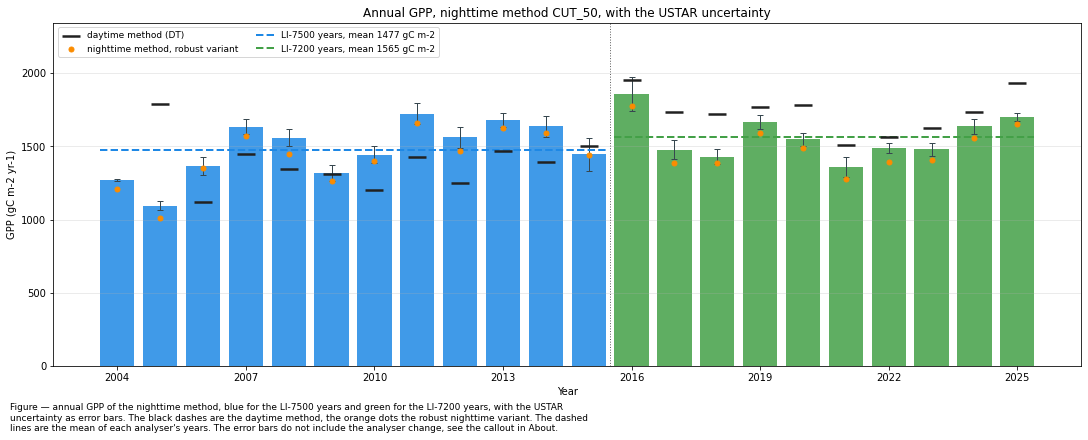

In [14]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.bar(annual.index, annual[f"GPP NT ({units_sum})"], color=annual['analyser'].map(ERA_COLORS), alpha=0.85,
       yerr=annual["USTAR unc. (NT)"], capsize=3, error_kw=dict(lw=1, ecolor='#37474F'))
ax.scatter(annual.index, annual["GPP DT"], marker='_', s=300, lw=2.5, color='#212121', zorder=5,
           label="daytime method (DT)")
ax.scatter(annual.index, annual["NT robust"], marker='o', s=25, color='#FB8C00', zorder=6,
           label="nighttime method, robust variant")
for _name, _c in ERA_COLORS.items():
    _x = annual.loc[annual['analyser'] == _name, f"GPP NT ({units_sum})"]
    ax.hlines(_x.mean(), _x.index.min() - 0.4, _x.index.max() + 0.4, color=_c, lw=2, ls='--',
              label=f"{_name} years, mean {_x.mean():.0f} {units_sum}")
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_ylim(0, annual[[f"GPP NT ({units_sum})", "GPP DT", "NT robust"]].max().max() * 1.2)
ax.set_xlabel("Year")
ax.set_ylabel(f"GPP ({units_sum} yr-1)")
ax.set_title("Annual GPP, nighttime method CUT_50, with the USTAR uncertainty")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9, ncol=2, loc='upper left')
year_axis(ax)
figcap(fig, "annual GPP of the nighttime method, blue for the LI-7500 years and green for the LI-7200 "
            "years, with the USTAR uncertainty as error bars. The black dashes are the daytime method, "
            "the orange dots the robust nighttime variant. The dashed lines are the mean of each "
            "analyser's years. The error bars do not include the analyser change, see the callout in "
            "About.")
fig.show()

## 📋 Table: the LI-7500 years against the LI-7200 years

In [15]:
# The two analysers' years side by side. A difference here mixes the forest, the weather, the
# instrument and the partitioning; the parallel period further below separates the instrument.
_cols = [f"GPP NT ({units_sum})", "NT robust", "GPP DT", "NT minus DT", "NEE measured (%)"]
_g = annual.groupby('analyser')[_cols]
eras = pd.concat({'mean': _g.mean(), 'SD between years': _g.std(), 'years': _g.count()}, axis=1)
eras = eras.loc[['LI-7500', 'LI-7200']]
eras.loc['difference (LI-7200 minus LI-7500)', 'mean'] = (eras.loc['LI-7200', 'mean']
                                                          - eras.loc['LI-7500', 'mean']).to_numpy()
display(styled(eras, caption=f"means of the annual GPP sums over the years of each analyser, "
                             f"{FIRST_YEAR}-2015 and 2016-{LAST_YEAR}, with the standard deviation "
                             f"between years. The daytime method of the LI-7500 years starts in "
                             f"{DT_FIRST_YEAR}",
               fmt="{:.0f}", cmap=None))

Table — means of the annual GPP sums over the years of each analyser, 2004-2015 and 2016-2025, with
the standard deviation between years. The daytime method of the LI-7500 years starts in 2005



</br>

# Nighttime and daytime method

The two methods use different parts of the same `NEE` record: the nighttime method the nights, the
daytime method the days. Where the analyser biases nighttime `NEE`, the nighttime method carries the
bias into `GPP`; the daytime method depends on the daytime records. A change in the difference
between the methods at 2016 therefore points at the measurement rather than at the forest.

## 📊 Plot: annual GPP of both methods and their monthly difference

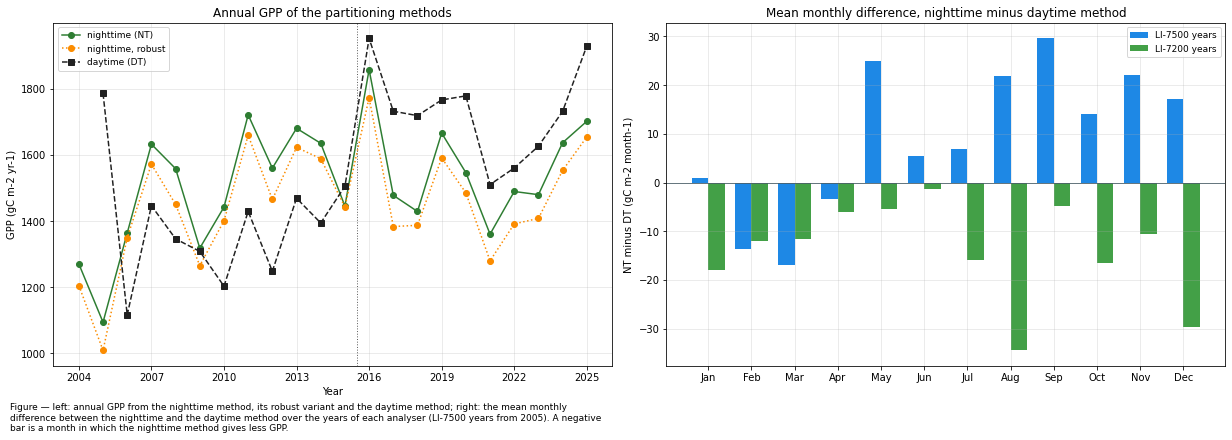

In [16]:
_nt_m = per_year_month(series, to_gc, month_names=False)
_dt_m = per_year_month(series_dt, to_gc, month_names=False)
_diff_m = _nt_m - _dt_m
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, layout="constrained")
axs[0].plot(annual.index, annual[f"GPP NT ({units_sum})"], color='#2E7D32', marker='o', label="nighttime (NT)")
axs[0].plot(annual.index, annual["NT robust"], color='#FB8C00', marker='o', ls=':', label="nighttime, robust")
axs[0].plot(annual.index, annual["GPP DT"], color='#212121', marker='s', ls='--', label="daytime (DT)")
axs[0].axvline(2015.5, color='#616161', lw=1, ls=':')
axs[0].set_xlabel("Year")
axs[0].set_ylabel(f"GPP ({units_sum} yr-1)")
axs[0].set_title("Annual GPP of the partitioning methods")
year_axis(axs[0])
_w = 0.38
for _off, (_name, _sel) in zip((-_w / 2, _w / 2), (('LI-7500', _diff_m.loc[:2015]),
                                                    ('LI-7200', _diff_m.loc[2016:]))):
    axs[1].bar(_diff_m.columns + _off, _sel.mean(), width=_w, color=ERA_COLORS[_name],
               label=f"{_name} years")
axs[1].axhline(0, color='#455A64', lw=0.8)
axs[1].set_xticks(range(1, 13), [calendar.month_abbr[m] for m in range(1, 13)])
axs[1].set_ylabel(f"NT minus DT ({units_sum} month-1)")
axs[1].set_title("Mean monthly difference, nighttime minus daytime method")
for _ax in axs:
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, f"left: annual GPP from the nighttime method, its robust variant and the daytime method; "
            f"right: the mean monthly difference between the nighttime and the daytime method over the "
            f"years of each analyser (LI-7500 years from {DT_FIRST_YEAR}). A negative bar is a month in "
            f"which the nighttime method gives less GPP.")
fig.show()

</br>

# Seasonality

## Monthly sums per year

### 📋 Table: monthly sums per year

In [17]:
monthly_sum = per_year_month(series, to_gc)
monthly_by_number = per_year_month(series, to_gc, month_names=False)
display(styled(monthly_sum, caption=f"monthly GPP sums ({units_sum}) of the nighttime method, one row per "
                                    f"year; the colour scale runs over the whole table",
               fmt="{:.0f}", cmap='Greens', axis=None))

Table — monthly GPP sums (gC m-2) of the nighttime method, one row per year; the colour scale runs
over the whole table



,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
YEAR,,,,,,,,,,,,
2004,18,10,57,102,186,222,220,208,166,65,17,-0
2005,-17,-13,6,44,171,230,220,213,160,59,11,10
2006,74,20,29,71,217,272,212,215,174,91,-16,5
2007,36,27,52,116,256,270,270,202,201,100,59,44
2008,22,27,38,84,253,284,259,209,202,107,38,37
2009,-45,-22,41,70,221,268,244,295,169,66,8,4
2010,30,9,-13,65,199,257,252,295,208,86,24,31
2011,-11,7,50,142,276,279,250,220,177,153,131,48
2012,39,-7,21,59,247,299,254,268,164,89,72,56


## Climatology per calendar month

### 📋 Table: climatology per calendar month

In [18]:
_by_month = monthly_by_number
climatology = pd.DataFrame({
    f"mean ({units_sum})": _by_month.mean(),
    "SD between years": _by_month.std(),
    "highest": _by_month.max(),
    "in": _by_month.idxmax(),
    "lowest": _by_month.min(),
    "in ": _by_month.idxmin(),
    "mean, LI-7500 years": _by_month.loc[:2015].mean(),
    "mean, LI-7200 years": _by_month.loc[2016:].mean(),
    "mean, DT": per_year_month(series_dt, to_gc, month_names=False).mean(),
})
climatology["LI-7200 minus LI-7500"] = climatology["mean, LI-7200 years"] - climatology["mean, LI-7500 years"]
climatology.index = [calendar.month_abbr[m] for m in climatology.index]
climatology.index.name = 'MONTH'
_fmt = {c: "{:.0f}" for c in climatology.columns}
_fmt["LI-7200 minus LI-7500"] = "{:+.0f}"
display(styled(climatology, caption=f"each calendar month across {FIRST_YEAR}-{LAST_YEAR} (nighttime "
                                    f"method): its mean sum, the spread between years, the years of "
                                    f"highest and lowest GPP, the mean over the years of each analyser, "
                                    f"and the mean of the daytime method ({DT_FIRST_YEAR}-{LAST_YEAR}). "
                                    f"The last column shows in which months the two analysers' years differ",
               fmt=_fmt, subset=["LI-7200 minus LI-7500"], cmap='RdBu', center=True))

Table — each calendar month across 2004-2025 (nighttime method): its mean sum, the spread between
years, the years of highest and lowest GPP, the mean over the years of each analyser, and the mean
of the daytime method (2005-2025). The last column shows in which months the two analysers' years
differ



,mean (gC m-2),SD between years,highest,in,lowest,in,"mean, LI-7500 years","mean, LI-7200 years","mean, DT",LI-7200 minus LI-7500
MONTH,,,,,,,,,,
Jan,8,27,74,2006,-45,2009,19,-5,16,-24
Feb,11,15,31,2014,-22,2009,8,14,24,+6
Mar,44,30,146,2016,-13,2010,34,55,57,+21
Apr,98,35,189,2016,44,2005,86,114,103,+28
May,235,51,295,2020,58,2021,234,236,227,+1
Jun,289,35,346,2025,222,2004,264,319,290,+55
Jul,267,35,341,2016,212,2006,249,289,273,+39
Aug,241,44,330,2013,189,2020,241,240,247,-1
Sep,193,22,248,2019,160,2005,184,203,181,+19


## Mean annual cycle

### 📊 Plot: mean annual cycle of daily GPP, per analyser

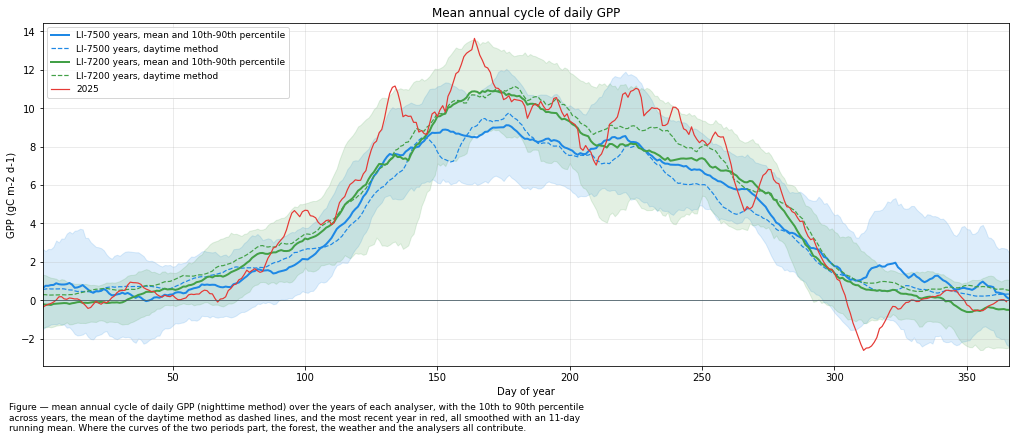

In [19]:
# Daily sums per day of year, smoothed with an 11-day running mean, for the years of each analyser.
fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
_sm = lambda s: s.rolling(11, center=True, min_periods=3).mean()
for _name, _sel in (('LI-7500', daily.loc[:'2015']), ('LI-7200', daily.loc['2016':])):
    _c = ERA_COLORS[_name]
    _g = _sel['GPP_NT'].groupby(_sel.index.dayofyear)
    ax.fill_between(_g.mean().index, _sm(_g.quantile(0.1)), _sm(_g.quantile(0.9)), color=_c, alpha=0.15)
    ax.plot(_g.mean().index, _sm(_g.mean()), color=_c, lw=2,
            label=f"{_name} years, mean and 10th-90th percentile")
    _gd = _sel['GPP_DT'].groupby(_sel.index.dayofyear).mean()
    ax.plot(_gd.index, _sm(_gd), color=_c, lw=1.2, ls='--', label=f"{_name} years, daytime method")
_last = daily.loc[str(LAST_YEAR), 'GPP_NT']
ax.plot(_last.index.dayofyear, _sm(_last), color='#E53935', lw=1.2, label=str(LAST_YEAR))
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_xlim(1, 366)
ax.set_xlabel("Day of year")
ax.set_ylabel(f"GPP ({units_sum} d-1)")
ax.set_title("Mean annual cycle of daily GPP")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='upper left')
figcap(fig, "mean annual cycle of daily GPP (nighttime method) over the years of each analyser, with the "
            "10th to 90th percentile across years, the mean of the daytime method as dashed lines, and "
            "the most recent year in red, all smoothed with an 11-day running mean. Where the curves of "
            "the two periods part, the forest, the weather and the analysers all contribute.")
fig.show()

## Mean diurnal cycle per month

### 📊 Plot: mean diurnal cycle per month, per analyser

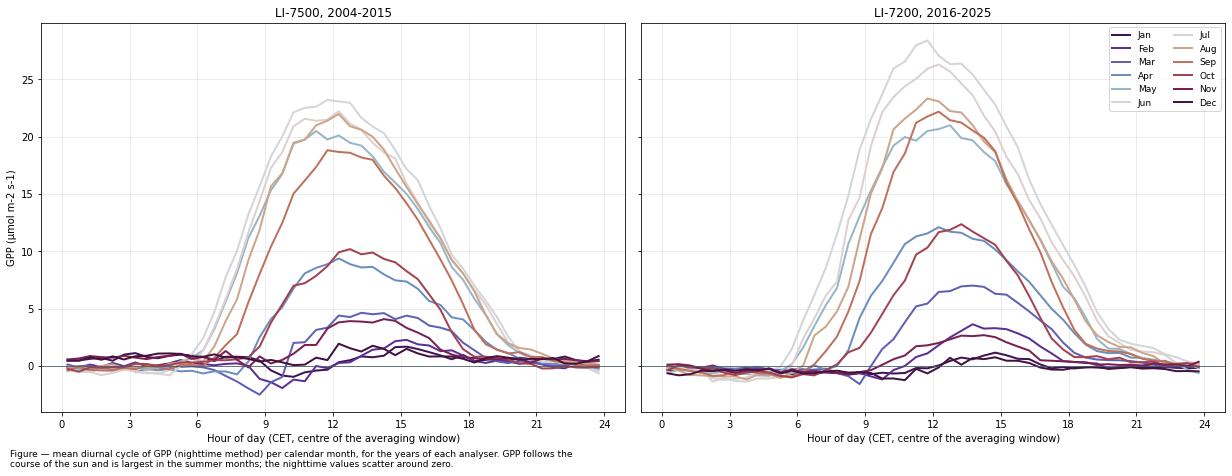

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
_colors = plt.get_cmap('twilight_shifted')(np.linspace(0.05, 0.95, 12))
for _ax, (_name, _s) in zip(axs, (('LI-7500, 2004-2015', series.loc[:'2015']),
                                  (f'LI-7200, 2016-{LAST_YEAR}', series.loc['2016':]))):
    _diurnal = _s.groupby([_s.index.month, _s.index.hour + _s.index.minute / 60]).mean().unstack(0)
    for _i, _month in enumerate(_diurnal.columns):
        _ax.plot(_diurnal.index, _diurnal[_month], color=_colors[_i], lw=2, label=calendar.month_abbr[_month])
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_xticks(range(0, 25, 3))
    _ax.set_xlabel("Hour of day (CET, centre of the averaging window)")
    _ax.set_title(_name)
    _ax.grid(alpha=0.3)
axs[0].set_ylabel(xlabel)
axs[1].legend(ncol=2, fontsize=9)
figcap(fig, "mean diurnal cycle of GPP (nighttime method) per calendar month, for the years of each "
            "analyser. GPP follows the course of the sun and is largest in the summer months; the "
            "nighttime values scatter around zero.")
fig.show()

## Month by hour

### 📊 Plot: month by hour, and the difference between the analysers' years

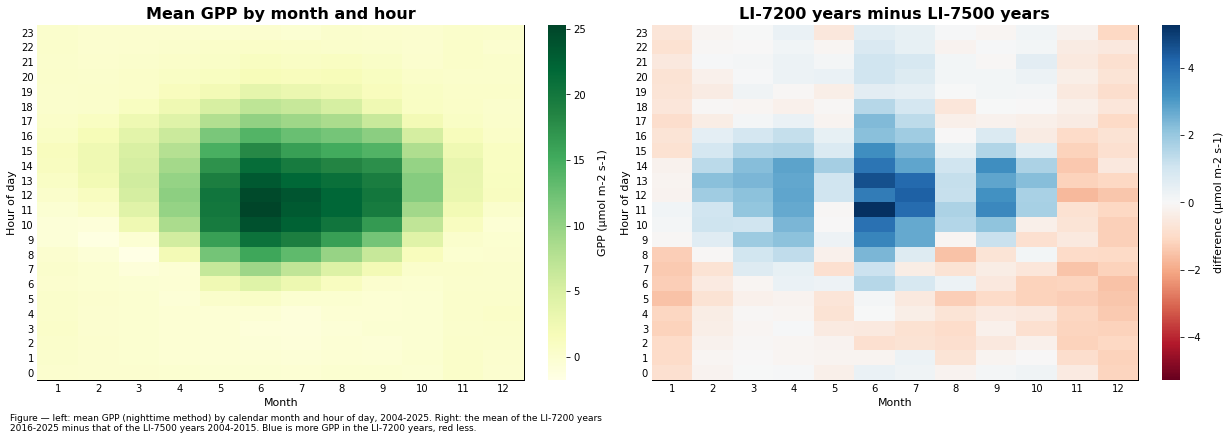

In [21]:
def _by_month_hour(s):
    """Mean of `s` per calendar month and hour, in the long form HeatmapXYZ expects."""
    frame = pd.DataFrame({'MONTH': s.index.month, 'HOUR': s.index.hour, 'z': s.to_numpy()})
    return frame.groupby(['MONTH', 'HOUR'], as_index=False)['z'].mean()


_all = _by_month_hour(series)
_diff = _by_month_hour(series.loc['2016':])
_diff['z'] = _diff['z'].to_numpy() - _by_month_hour(series.loc[:'2015'])['z'].to_numpy()
_absmax = _diff['z'].abs().max()
_style = dict(axlabel_fontsize=11, ticks_fontsize=10)
fig, axs = plt.subplots(ncols=2, figsize=(17, 6), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_all['MONTH'], y=_all['HOUR'], z=_all['z']).plot(
    ax=axs[0], cmap='YlGn', xlabel="Month", ylabel="Hour of day", zlabel=xlabel, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"Mean {var} by month and hour", **_style))
dv.plotting.HeatmapXYZ(x=_diff['MONTH'], y=_diff['HOUR'], z=_diff['z']).plot(
    ax=axs[1], cmap='RdBu', vmin=-_absmax, vmax=_absmax, xlabel="Month", ylabel="Hour of day",
    zlabel=f"difference ({units})", cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="LI-7200 years minus LI-7500 years", **_style))
figcap(fig, f"left: mean GPP (nighttime method) by calendar month and hour of day, "
            f"{FIRST_YEAR}-{LAST_YEAR}. Right: the mean of the LI-7200 years 2016-{LAST_YEAR} minus that "
            f"of the LI-7500 years 2004-2015. Blue is more GPP in the LI-7200 years, red less.")

</br>

# Growing season

The growing season is defined here from `GPP` itself. Daily `GPP` of the nighttime method is
smoothed with a running mean (window in Settings), and the season is the longest run of days in
which the smoothed value exceeds a fixed fraction of that year's peak (fraction in Settings). A
fraction of the peak rather than a fixed value lets the rule work in years of low and of high `GPP`
alike. The evergreen part of the mixed forest takes up some carbon in winter as well, so the season
does not start from zero.

## 📋 Table: growing season per year

In [22]:
_smooth = daily['GPP_NT'].rolling(GS_SMOOTHING_DAYS, center=True, min_periods=GS_SMOOTHING_DAYS // 2).mean()
_rows = {}
for _y in range(FIRST_YEAR, LAST_YEAR + 1):
    _s = _smooth.loc[str(_y)]
    _threshold = GS_FRACTION * _s.max()
    _len, _start = longest_spell(_s > _threshold)
    _end = _start + pd.Timedelta(days=_len - 1)
    _rows[_y] = {'analyser': era(_y), 'start': _start, 'end': _end, 'length (d)': _len,
                 'start (day of year)': _start.dayofyear, 'end (day of year)': _end.dayofyear,
                 f"peak ({units_sum} d-1)": _s.max(), 'peak (day of year)': _s.idxmax().dayofyear,
                 f"threshold ({units_sum} d-1)": _threshold,
                 f"GPP in the season ({units_sum})": daily.loc[_start:_end, 'GPP_NT'].sum(),
                 "share of the annual GPP (%)": 100 * daily.loc[_start:_end, 'GPP_NT'].sum()
                                                 / daily.loc[str(_y), 'GPP_NT'].sum()}
season = pd.DataFrame.from_dict(_rows, orient='index')
season.index.name = 'YEAR'
_show = season.copy()
_show['start'] = _show['start'].dt.strftime('%d %b')
_show['end'] = _show['end'].dt.strftime('%d %b')
_fmt = {c: "{:.0f}" for c in _show.columns}
_fmt.update({f"peak ({units_sum} d-1)": "{:.2f}", f"threshold ({units_sum} d-1)": "{:.2f}",
             "share of the annual GPP (%)": "{:.1f}"})
display(styled(_show, caption=f"growing season per year: the longest run of days in which the "
                              f"{GS_SMOOTHING_DAYS}-day running mean of daily GPP (nighttime method) "
                              f"exceeds {GS_FRACTION:.0%} of that year's peak, with the peak itself, "
                              f"the GPP summed inside the season and its share of the annual sum",
               fmt=_fmt, subset=['length (d)'], cmap='Greens'))

Table — growing season per year: the longest run of days in which the 15-day running mean of daily
GPP (nighttime method) exceeds 20% of that year's peak, with the peak itself, the GPP summed inside
the season and its share of the annual sum



,analyser,start,end,length (d),start (day of year),end (day of year),peak (gC m-2 d-1),peak (day of year),threshold (gC m-2 d-1),GPP in the season (gC m-2),share of the annual GPP (%)
YEAR,,,,,,,,,,,
2004,LI-7500,13 Mar,21 Oct,223,73,295,8.12,191,1.62,1204,94.8
2005,LI-7500,20 Apr,04 Oct,168,110,277,8.68,162,1.74,1024,93.6
2006,LI-7500,04 Apr,26 Oct,206,94,299,9.46,170,1.89,1239,90.8
2007,LI-7500,10 Apr,17 Oct,191,100,290,9.64,174,1.93,1394,85.4
2008,LI-7500,16 Apr,04 Nov,203,107,309,10.40,150,2.08,1369,87.8
2009,LI-7500,16 Apr,21 Oct,189,106,294,10.25,228,2.05,1304,98.9
2010,LI-7500,17 Apr,24 Oct,191,107,297,11.98,218,2.40,1329,92.1
2011,LI-7500,17 Mar,08 Dec,267,76,342,10.02,158,2.00,1686,98.0
2012,LI-7500,22 Apr,13 Oct,175,113,287,12.17,173,2.43,1303,83.5


## 📊 Plot: start, end and length of the growing season

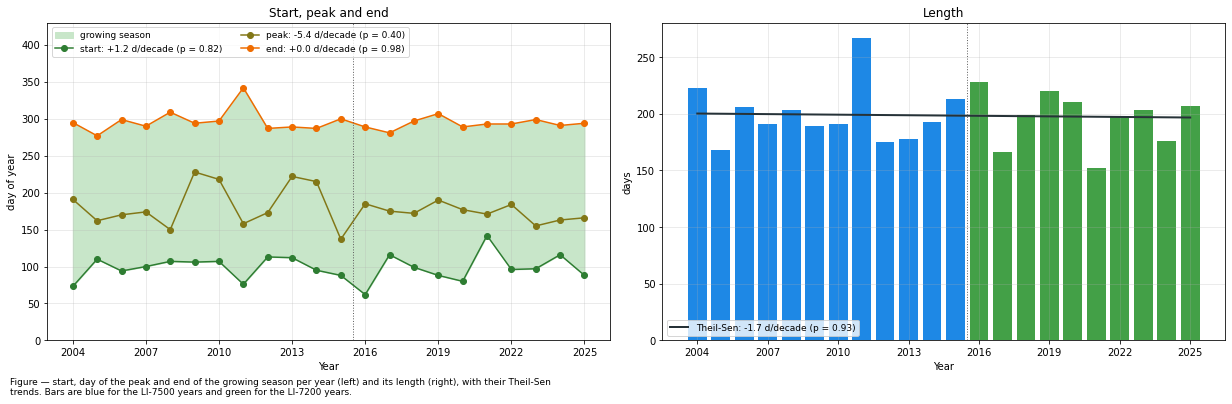

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5), dpi=72, layout="constrained")
axs[0].fill_between(season.index, season['start (day of year)'], season['end (day of year)'], color='#C8E6C9',
                    label="growing season")
for _c, _col in (('start (day of year)', '#2E7D32'), ('peak (day of year)', '#827717'),
                 ('end (day of year)', '#EF6C00')):
    _fit = trend(season[_c])
    axs[0].plot(season.index, season[_c], marker='o', color=_col, lw=1.5,
                label=f"{_c.split(' ')[0]}: {_fit['slope']:+.1f} d/decade (p = {_fit['pvalue']:.2f})")
axs[0].set_ylabel("day of year")
axs[0].set_title("Start, peak and end")
axs[0].set_ylim(0, 430)  # room for the legend above the season
_fit = trend(season['length (d)'])
axs[1].bar(season.index, season['length (d)'], color=season['analyser'].map(ERA_COLORS))
axs[1].plot(_fit['fit'].index, _fit['fit'], color='#263238', lw=2,
            label=f"Theil-Sen: {_fit['slope']:+.1f} d/decade (p = {_fit['pvalue']:.2f})")
axs[1].set_ylabel("days")
axs[1].set_title("Length")
for _ax in axs:
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.set_xlabel("Year")
    _ax.grid(alpha=0.3)
    year_axis(_ax)
axs[0].legend(fontsize=9, loc='upper left', ncol=2)
axs[1].legend(fontsize=9, loc='lower left')
figcap(fig, "start, day of the peak and end of the growing season per year (left) and its length "
            "(right), with their Theil-Sen trends. Bars are blue for the LI-7500 years and green for "
            "the LI-7200 years.")
fig.show()

</br>

# Extremes

From the daily sums of the nighttime method, with the daytime method and the measured share of the
underlying `NEE` listed beside them.

## The days of highest and lowest GPP

### 📋 Table: the days of highest GPP

In [24]:
def _ranked_days(_label, _ranked):
    _table = pd.DataFrame({"date": [f"{_d:%d %b %Y}" for _d in _ranked.index],
                           f"GPP NT ({units_sum} d-1)": _ranked.to_numpy(),
                           f"GPP DT ({units_sum} d-1)": daily.loc[_ranked.index, 'GPP_DT'].to_numpy(),
                           f"NEE ({units_sum} d-1)": daily.loc[_ranked.index, 'NEE'].to_numpy(),
                           "NEE measured (%)": daily.loc[_ranked.index, 'NEE measured (%)'].to_numpy(),
                           "NEE measured, day (%)": daily.loc[_ranked.index, 'NEE measured, day (%)'].to_numpy(),
                           "analyser": [era(_d.year) for _d in _ranked.index]},
                          index=range(1, N_EXTREMES + 1))
    _table.index.name = "rank"
    display(styled(_table, caption=f"the {N_EXTREMES} days of {_label} in {FIRST_YEAR}-{LAST_YEAR}, with "
                                   f"the daytime method, the daily NEE and the measured share of the "
                                   f"day's NEE. Where the two methods differ by much, at least one of "
                                   f"their fits does not describe that day well",
                   fmt={f"GPP NT ({units_sum} d-1)": "{:.2f}", f"GPP DT ({units_sum} d-1)": "{:.2f}",
                        f"NEE ({units_sum} d-1)": "{:.2f}", "NEE measured (%)": "{:.0f}",
                        "NEE measured, day (%)": "{:.0f}"},
                   subset=["NEE measured (%)", "NEE measured, day (%)"], cmap='Blues'))


_ranked_days('highest GPP (nighttime method)', daily['GPP_NT'].nlargest(N_EXTREMES))

Table — the 10 days of highest GPP (nighttime method) in 2004-2025, with the daytime method, the
daily NEE and the measured share of the day's NEE. Where the two methods differ by much, at least
one of their fits does not describe that day well



,date,GPP NT (gC m-2 d-1),GPP DT (gC m-2 d-1),NEE (gC m-2 d-1),NEE measured (%),"NEE measured, day (%)",analyser
rank,,,,,,,
1,09 Jun 2025,16.30,17.43,-10.40,40,58,LI-7200
2,01 Jul 2016,16.20,20.95,-9.22,52,69,LI-7200
3,10 Aug 2013,15.98,15.94,-5.15,15,25,LI-7500
4,04 Aug 2010,15.98,2.66,-5.67,25,31,LI-7500
5,07 Jun 2024,15.97,5.54,-7.87,56,68,LI-7200
6,14 Jun 2025,15.94,12.29,-7.72,40,58,LI-7200
7,17 Jun 2021,15.92,10.62,-8.00,52,59,LI-7200
8,28 May 2008,15.79,13.99,-7.91,85,97,LI-7500
9,03 Jul 2016,15.78,20.18,-9.29,40,59,LI-7200


### 📋 Table: the days of lowest GPP

In [25]:
# The lowest daily sums fall in winter. A negative daily sum is not physical; it shows where the
# nighttime method's RECO lies below the NEE of the day.
_ranked_days('lowest GPP (nighttime method)', daily['GPP_NT'].nsmallest(N_EXTREMES))

Table — the 10 days of lowest GPP (nighttime method) in 2004-2025, with the daytime method, the
daily NEE and the measured share of the day's NEE. Where the two methods differ by much, at least
one of their fits does not describe that day well



,date,GPP NT (gC m-2 d-1),GPP DT (gC m-2 d-1),NEE (gC m-2 d-1),NEE measured (%),"NEE measured, day (%)",analyser
rank,,,,,,,
1,13 Dec 2022,-8.99,0.00,12.58,52,62,LI-7200
2,08 Dec 2013,-7.48,0.00,7.73,29,53,LI-7500
3,28 Nov 2013,-6.95,0.06,7.92,29,35,LI-7500
4,20 Nov 2010,-6.75,0.00,7.02,48,53,LI-7500
5,17 Dec 2022,-6.71,0.00,9.52,71,75,LI-7200
6,27 Nov 2006,-6.66,0.00,7.26,10,29,LI-7500
7,21 Dec 2014,-6.53,0.43,12.48,88,81,LI-7500
8,28 Nov 2010,-6.11,0.00,6.30,33,59,LI-7500
9,13 Jan 2009,-6.03,0.00,6.06,25,29,LI-7500


## 📋 Table: highest half-hourly GPP per year

In [26]:
# Half-hours with measured NEE only: there GPP is modelled RECO minus a measured flux. Elsewhere it
# is a model value throughout.
_gpp_meas = series.where(nee_is_measured)
_idx = _gpp_meas.groupby(_gpp_meas.index.year).idxmax()
_peaks = pd.DataFrame({'analyser': [era(y) for y in _idx.index],
                       f"highest GPP NT ({units})": _gpp_meas.loc[_idx.to_numpy()].to_numpy(),
                       'averaging window': [window(t) for t in _idx.to_numpy()],
                       f"99th percentile, NT ({units})": _gpp_meas.groupby(_gpp_meas.index.year).quantile(0.99),
                       f"99th percentile, DT ({units})": series_dt.where(nee_is_measured).groupby(
                           series_dt.index.year).quantile(0.99)}, index=_idx.index)
_peaks.index.name = 'YEAR'
display(styled(_peaks, caption=f"the highest half-hourly GPP of each year on half-hours with measured NEE, "
                               f"and the 99th percentile of GPP on these half-hours for both methods, "
                               f"which is less sensitive to a single half-hour. A maximum outside the "
                               f"summer comes from one half-hour of measured NEE far below the "
                               f"modelled RECO",
               fmt={f"highest GPP NT ({units})": "{:.1f}", f"99th percentile, NT ({units})": "{:.1f}",
                    f"99th percentile, DT ({units})": "{:.1f}"},
               subset=[f"99th percentile, NT ({units})", f"99th percentile, DT ({units})"], cmap='Greens'))

Table — the highest half-hourly GPP of each year on half-hours with measured NEE, and the 99th
percentile of GPP on these half-hours for both methods, which is less sensitive to a single half-
hour. A maximum outside the summer comes from one half-hour of measured NEE far below the modelled
RECO



,analyser,highest GPP NT (µmol m-2 s-1),averaging window,"99th percentile, NT (µmol m-2 s-1)","99th percentile, DT (µmol m-2 s-1)"
YEAR,,,,,
2004,LI-7500,51.7,"09 Jul 2004, 09:30 to 10:00",32.2,-
2005,LI-7500,53.0,"27 Apr 2005, 08:00 to 08:30",33.1,19.5
2006,LI-7500,51.3,"22 Nov 2006, 10:30 to 11:00",32.4,23.8
2007,LI-7500,54.2,"25 Nov 2007, 06:30 to 07:00",36.2,30.5
2008,LI-7500,55.8,"30 Jun 2008, 12:00 to 12:30",37.8,28.6
2009,LI-7500,53.6,"11 Jun 2009, 08:00 to 08:30",37.3,28.0
2010,LI-7500,55.7,"06 Aug 2010, 12:00 to 12:30",37.5,27.6
2011,LI-7500,53.3,"08 Nov 2011, 09:00 to 09:30",39.2,28.3
2012,LI-7500,56.5,"19 Jun 2012, 09:30 to 10:00",40.2,28.0


</br>

# Light response

The response of `GPP` to incoming shortwave radiation in summer, for the years of each analyser.
The nighttime method is shown on half-hours with measured `NEE`, so the curve follows the
measurement. The daytime method fits a light response by construction, so its curve shows the
fitted model on the same half-hours. If the change of analyser had shifted the flux, the curves of
the two periods would part under the same light. Weather and the forest itself change the curves as
well, so a difference is a hint, not a proof.

## 📊 Plot: light response of GPP, per analyser

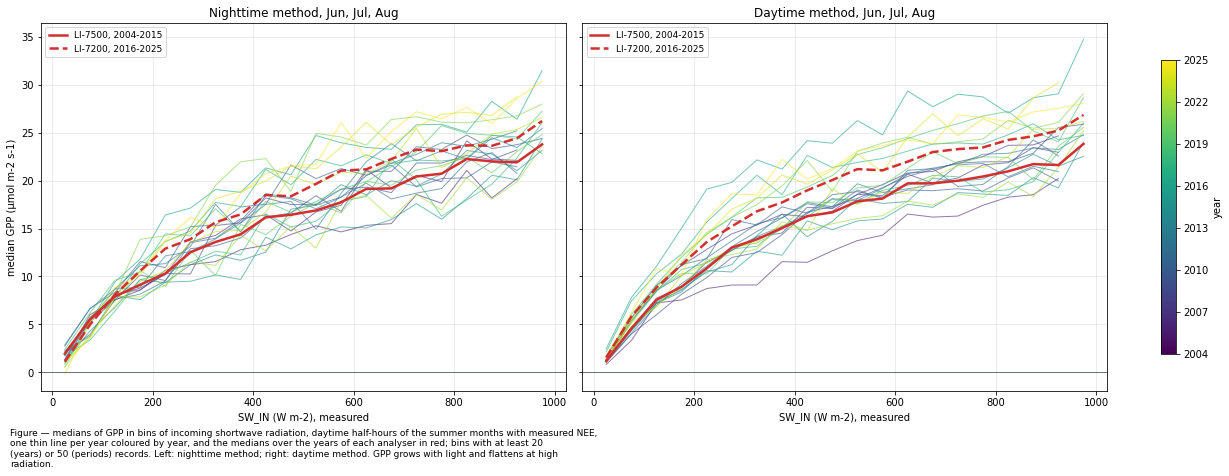

In [27]:
_bins_light = np.arange(0, 1001, 50)
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
_day = df.loc[nee_is_measured & is_day & df.index.month.isin(LIGHT_MONTHS), [varname, varname_dt, SW_IN]]
_day = _day.dropna(subset=[SW_IN])
_cmap = plt.get_cmap('viridis')


def _binned(d, col, bins, min_count):
    """Median of `col` per bin of SW_IN, for bins holding at least `min_count` records."""
    _g = d.groupby(pd.cut(d[SW_IN], bins), observed=True)[col]
    _med = _g.median()[_g.count() >= min_count]
    return [i.mid for i in _med.index], _med.to_numpy()


for _ax, _col in ((axs[0], varname), (axs[1], varname_dt)):
    _d = _day.dropna(subset=[_col])
    for _y in range(FIRST_YEAR, LAST_YEAR + 1):
        _sel = _d[_d.index.year == _y]
        if len(_sel) < 200:
            continue
        _ax.plot(*_binned(_sel, _col, _bins_light, 20),
                 color=_cmap((_y - FIRST_YEAR) / (LAST_YEAR - FIRST_YEAR)), lw=1, alpha=0.6)
    for _name, _years, _ls in (('LI-7500, 2004-2015', _d.index.year < 2016, '-'),
                               (f'LI-7200, 2016-{LAST_YEAR}', _d.index.year >= 2016, '--')):
        _ax.plot(*_binned(_d[_years], _col, _bins_light, 50), color='#D32F2F', lw=2.5, ls=_ls, label=_name)
    _ax.set_xlabel("SW_IN (W m-2), measured")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9, loc='upper left')
_months = ', '.join(calendar.month_abbr[m] for m in LIGHT_MONTHS)
axs[0].set_title(f"Nighttime method, {_months}")
axs[1].set_title(f"Daytime method, {_months}")
axs[0].set_ylabel(f"median GPP ({units})")
_sm = plt.cm.ScalarMappable(cmap=_cmap, norm=Normalize(FIRST_YEAR, LAST_YEAR))
_cb = fig.colorbar(_sm, ax=axs, label="year", shrink=0.8)
_cb.locator = plt.MaxNLocator(integer=True)
_cb.update_ticks()
figcap(fig, "medians of GPP in bins of incoming shortwave radiation, daytime half-hours of the summer "
            "months with measured NEE, one thin line per year coloured by year, and the medians over the "
            "years of each analyser in red; bins with at least 20 (years) or 50 (periods) records. "
            "Left: nighttime method; right: daytime method. GPP grows with light and flattens at high "
            "radiation.")
fig.show()

## 📋 Table: light response per analyser

In [28]:
def _response(d, col, lo, hi):
    """Median of `col` on the records with SW_IN between `lo` and `hi`."""
    return d.loc[(d[SW_IN] >= lo) & (d[SW_IN] < hi), col].median()


_rows = {}
for _name, _sel in (('LI-7500, 2004-2015', _day.index.year < 2016),
                    (f'LI-7200, 2016-{LAST_YEAR}', _day.index.year >= 2016)):
    _d = _day[_sel]
    _rows[_name] = {f"NT at SW_IN 700-900 W m-2 ({units})": _response(_d, varname, 700, 900),
                    f"NT at SW_IN 100-200 W m-2 ({units})": _response(_d, varname, 100, 200),
                    f"DT at SW_IN 700-900 W m-2 ({units})": _response(_d, varname_dt, 700, 900),
                    f"DT at SW_IN 100-200 W m-2 ({units})": _response(_d, varname_dt, 100, 200),
                    "records": len(_d)}
responses = pd.DataFrame.from_dict(_rows, orient='index')
responses.loc['difference'] = responses.iloc[1] - responses.iloc[0]
responses.loc['difference', 'records'] = np.nan
display(styled(responses, caption=f"median GPP of both methods under bright and under dim summer daylight "
                                  f"({_months}), on daytime half-hours with measured NEE, for the years "
                                  f"of each analyser",
               fmt={c: ("{:.0f}" if c == 'records' else "{:.2f}") for c in responses.columns}, cmap=None))

Table — median GPP of both methods under bright and under dim summer daylight (Jun, Jul, Aug), on
daytime half-hours with measured NEE, for the years of each analyser



,NT at SW_IN 700-900 W m-2 (µmol m-2 s-1),NT at SW_IN 100-200 W m-2 (µmol m-2 s-1),DT at SW_IN 700-900 W m-2 (µmol m-2 s-1),DT at SW_IN 100-200 W m-2 (µmol m-2 s-1),records
"LI-7500, 2004-2015",21.50,8.49,20.88,8.26,13584
"LI-7200, 2016-2025",23.44,9.26,23.93,9.94,17380
difference,1.94,0.78,3.05,1.68,-


</br>

# The two analysers in parallel

From 11 January 2016 to 12 December 2017 both analysers measured, and each per-analyser record was
partitioned on its own. The merged record uses the LI-7200; this section reads both per-analyser
records over these two years. On the half-hours where both measured `NEE`, the comparison is the
closest one possible. Over all half-hours it includes the gap-filling and the respiration model,
which the LI-7500 fits on fewer and drier nights.

In [29]:
_cols = [varname, varname_dt, nee_measured]
par = pd.concat({'IRGA75': pd.read_parquet(Path(DATADIR) / FILE_IRGA75, columns=_cols),
                 'IRGA72': pd.read_parquet(Path(DATADIR) / FILE_IRGA72, columns=_cols)}, axis=1)
par = par.loc[PARALLEL[0]:PARALLEL[1] + ' 23:45']
both_measured = par.xs(nee_measured, axis=1, level=1).notna().all(axis=1)
assert par.xs(varname, axis=1, level=1).notna().all().all(), "GPP missing in a per-analyser record"
print(f"Parallel period:    {par.index[0]} -> {par.index[-1]} ({len(par):,} half-hours)")
print(f"Both measured NEE:  {both_measured.sum():,} half-hours ({100 * both_measured.mean():.1f} %)")
for _a in ('IRGA75', 'IRGA72'):
    print(f"{_a} measured NEE:  {par[(_a, nee_measured)].notna().mean() * 100:.1f} %")

Parallel period:    2016-01-11 00:15:00 -> 2017-12-12 23:45:00 (33,696 half-hours)
Both measured NEE:  10,276 half-hours (30.5 %)
IRGA75 measured NEE:  40.1 %
IRGA72 measured NEE:  43.4 %


## 📋 Table: sums of both analysers in the parallel period

In [30]:
_is_day = df_full.loc[par.index, DAYTIME].eq(1).to_numpy()
_rows = {}
for _method, _col in (('nighttime (NT)', varname), ('daytime (DT)', varname_dt)):
    for _label, _rec in (("half-hours both measured NEE", both_measured.to_numpy()),
                         ("all half-hours", np.ones(len(par), dtype=bool))):
        for _part, _mask in (("all", np.ones(len(par), dtype=bool)), ("day", _is_day), ("night", ~_is_day)):
            _m = _rec & _mask
            _a, _b = to_gc(par.loc[_m, ('IRGA75', _col)]), to_gc(par.loc[_m, ('IRGA72', _col)])
            _rows[(_method, _label, _part)] = {f"LI-7500 ({units_sum})": _a, f"LI-7200 ({units_sum})": _b,
                                               f"LI-7500 minus LI-7200 ({units_sum})": _a - _b,
                                               # Nighttime sums are close to zero, so a relative
                                               # difference is given only where GPP is large.
                                               "LI-7500 minus LI-7200 (%)": (100 * (_a - _b) / _b
                                                                             if _part != 'night' else np.nan)}
parallel = pd.DataFrame.from_dict(_rows, orient='index')
parallel.index.names = ['method', 'records', 'part of day']
display(styled(parallel, caption=f"GPP summed over {PARALLEL[0]} to {PARALLEL[1]} for both analysers and "
                                 f"both methods: on the half-hours where both measured NEE, and over all "
                                 f"half-hours. A negative difference is less GPP from the LI-7500. "
                                 f"Nighttime sums are close to zero and have no relative difference",
               fmt={f"LI-7500 ({units_sum})": "{:.0f}", f"LI-7200 ({units_sum})": "{:.0f}",
                    f"LI-7500 minus LI-7200 ({units_sum})": "{:+.0f}", "LI-7500 minus LI-7200 (%)": "{:+.1f}"},
               subset=[f"LI-7500 minus LI-7200 ({units_sum})"], cmap='RdBu', center=True))

Table — GPP summed over 2016-01-11 to 2017-12-12 for both analysers and both methods: on the half-
hours where both measured NEE, and over all half-hours. A negative difference is less GPP from the
LI-7500. Nighttime sums are close to zero and have no relative difference



## 📊 Plot: cumulative GPP of both analysers in the parallel period

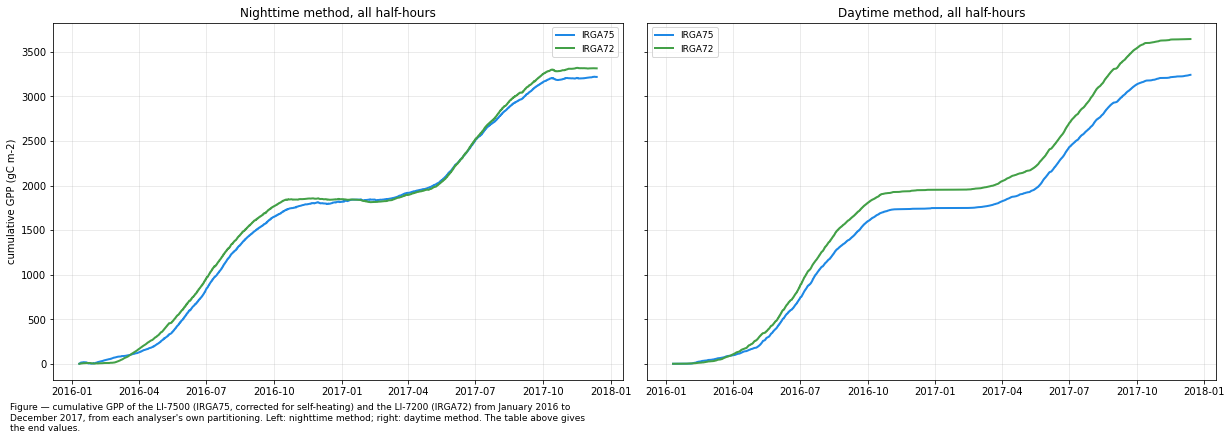

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, sharey=True, layout="constrained")
for _ax, _col, _title in ((axs[0], varname, "Nighttime method"), (axs[1], varname_dt, "Daytime method")):
    for _a, _c in (('IRGA75', '#1E88E5'), ('IRGA72', '#43A047')):
        _ax.plot(par.index, par[(_a, _col)].cumsum() * UMOL_TO_GC, color=_c, lw=2, label=_a)
    _ax.set_title(f"{_title}, all half-hours")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
axs[0].set_ylabel(f"cumulative GPP ({units_sum})")
figcap(fig, "cumulative GPP of the LI-7500 (IRGA75, corrected for self-heating) and the LI-7200 (IRGA72) "
            "from January 2016 to December 2017, from each analyser's own partitioning. Left: nighttime "
            "method; right: daytime method. The table above gives the end values.")
fig.show()

## 📊 Plot: the two analysers day by day

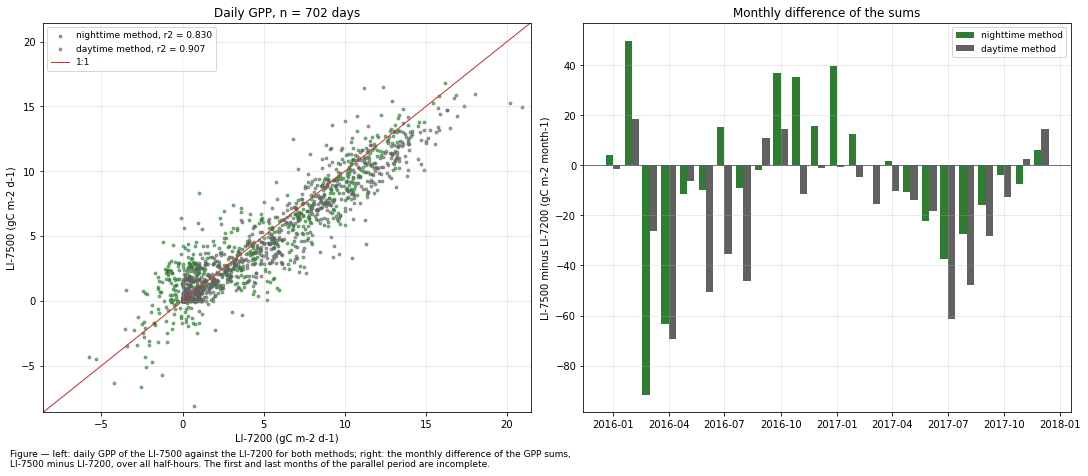

In [32]:
_d = par.xs(varname, axis=1, level=1).resample('D').sum() * UMOL_TO_GC
_dd = par.xs(varname_dt, axis=1, level=1).resample('D').sum() * UMOL_TO_GC
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), dpi=72, layout="constrained")
_lim = (min(_d.min().min(), _dd.min().min()) - 0.5, max(_d.max().max(), _dd.max().max()) + 0.5)
axs[0].scatter(_d['IRGA72'], _d['IRGA75'], s=8, color='#2E7D32', alpha=0.6,
               label=f"nighttime method, r2 = {_d['IRGA72'].corr(_d['IRGA75']) ** 2:.3f}")
axs[0].scatter(_dd['IRGA72'], _dd['IRGA75'], s=8, color='#616161', alpha=0.6,
               label=f"daytime method, r2 = {_dd['IRGA72'].corr(_dd['IRGA75']) ** 2:.3f}")
axs[0].plot(_lim, _lim, color='#D32F2F', lw=1, label='1:1')
axs[0].set_xlim(_lim)
axs[0].set_ylim(_lim)
axs[0].set_xlabel(f"LI-7200 ({units_sum} d-1)")
axs[0].set_ylabel(f"LI-7500 ({units_sum} d-1)")
axs[0].set_title(f"Daily GPP, n = {len(_d):,} days")
axs[0].legend(fontsize=9)
_m = (par.xs(varname, axis=1, level=1)['IRGA75'] - par.xs(varname, axis=1, level=1)['IRGA72'])
_m = _m.resample('MS').sum() * UMOL_TO_GC
_mdt = (par.xs(varname_dt, axis=1, level=1)['IRGA75'] - par.xs(varname_dt, axis=1, level=1)['IRGA72'])
_mdt = _mdt.resample('MS').sum() * UMOL_TO_GC
axs[1].bar(_m.index - pd.Timedelta('6D'), _m, width=12, color='#2E7D32', label="nighttime method")
axs[1].bar(_mdt.index + pd.Timedelta('6D'), _mdt, width=12, color='#616161', label="daytime method")
axs[1].axhline(0, color='#455A64', lw=0.8)
axs[1].set_ylabel(f"LI-7500 minus LI-7200 ({units_sum} month-1)")
axs[1].set_title("Monthly difference of the sums")
axs[1].legend(fontsize=9)
for _ax in axs:
    _ax.grid(alpha=0.3)
figcap(fig, "left: daily GPP of the LI-7500 against the LI-7200 for both methods; right: the monthly "
            "difference of the GPP sums, LI-7500 minus LI-7200, over all half-hours. The first and last "
            "months of the parallel period are incomplete.")
fig.show()

</br>

# Heatmap plots

## Half-hourly

### 📊 Plot: heatmap of the half-hourly values

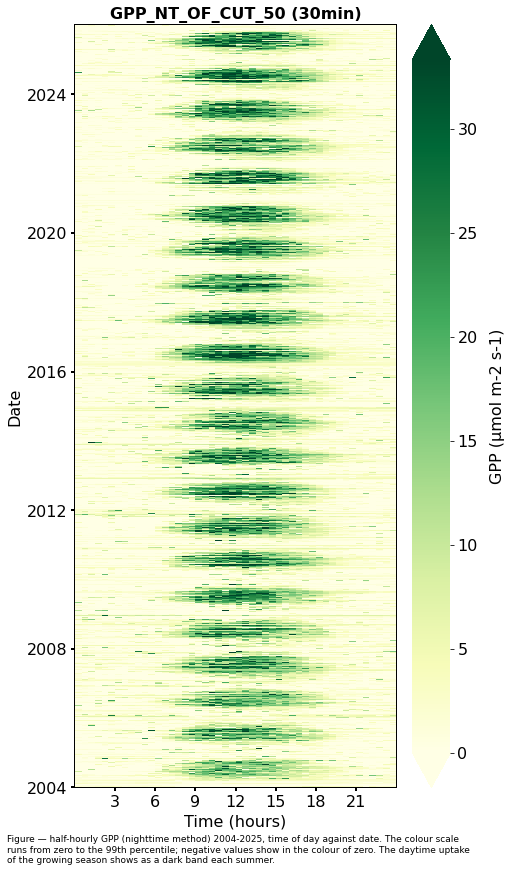

In [33]:
_hi = series.quantile(0.99)
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapDateTime(series=series).plot(ax=ax, cmap='YlGn', vmin=0, vmax=_hi,
                                                cb_extend='both', zlabel=xlabel)
figcap(fig, f"half-hourly GPP (nighttime method) {FIRST_YEAR}-{LAST_YEAR}, time of day against date. The "
            f"colour scale runs from zero to the 99th percentile; negative values show in the colour of "
            f"zero. The daytime uptake of the growing season shows as a dark band each summer.")

## Monthly

### 📊 Plot: monthly sums and their ranks

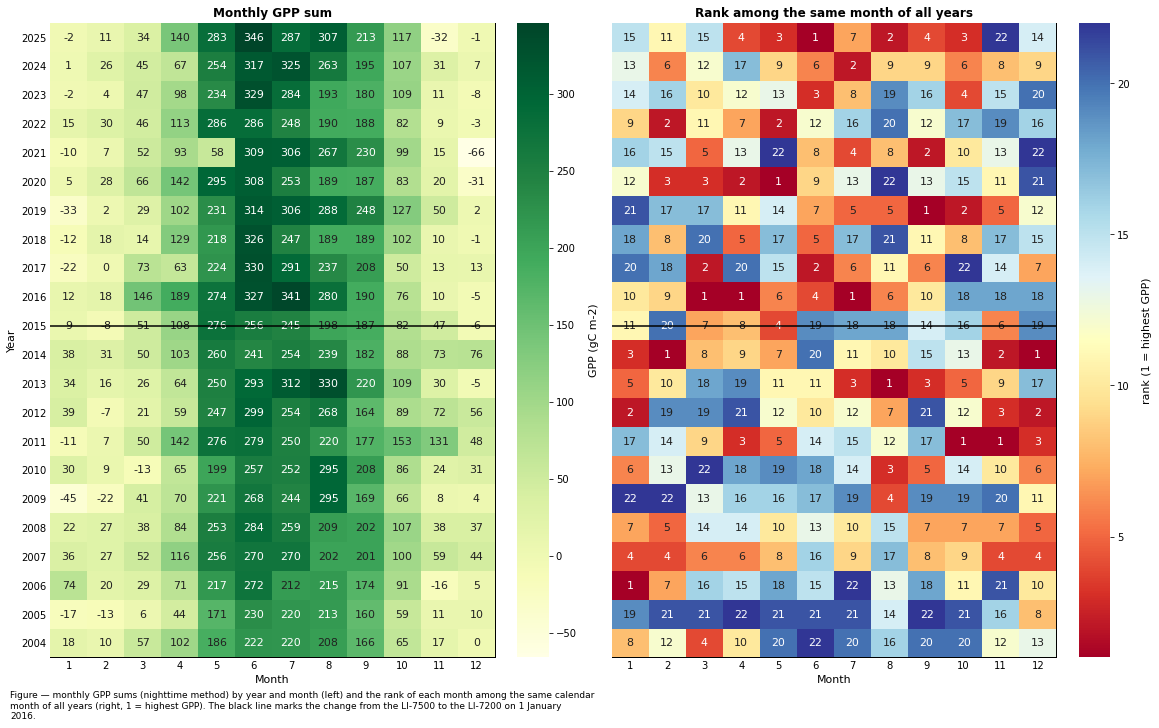

In [34]:
fig, axs = plt.subplots(ncols=2, figsize=(16, 10), dpi=72, sharey=True, layout="constrained")
_style = dv.plotting.FormatStyle(axlabel_fontsize=11, ticks_fontsize=10)
_long = monthly_by_number.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=axs[0], cmap='YlGn', vmin=min(0, _long['z'].min()), xlabel="Month", ylabel="Year",
    zlabel=f"GPP ({units_sum})", show_values=True, cb_labelsize=10, format_style=_style)
# Rank 1 is the month of highest GPP among the same calendar month of all years.
_ranks = monthly_by_number.rank(axis=0, ascending=False).stack().rename('z').reset_index()
_ranks.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_ranks['MONTH'], y=_ranks['YEAR'], z=_ranks['z']).plot(
    ax=axs[1], cmap='RdYlBu', xlabel="Month", ylabel="", zlabel="rank (1 = highest GPP)",
    show_values=True, cb_labelsize=10, format_style=_style)
for _ax, _title in zip(axs, ["Monthly GPP sum", "Rank among the same month of all years"]):
    _ax.set_title(_title, fontsize=12, fontweight='bold', color='black')
    _ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, f"monthly GPP sums (nighttime method) by year and month (left) and the rank of each month "
            f"among the same calendar month of all years (right, 1 = highest GPP). The black line marks "
            f"the change from the LI-7500 to the LI-7200 on 1 January 2016.")

## Anomaly by year and month

### 📊 Plot: anomaly by year and month

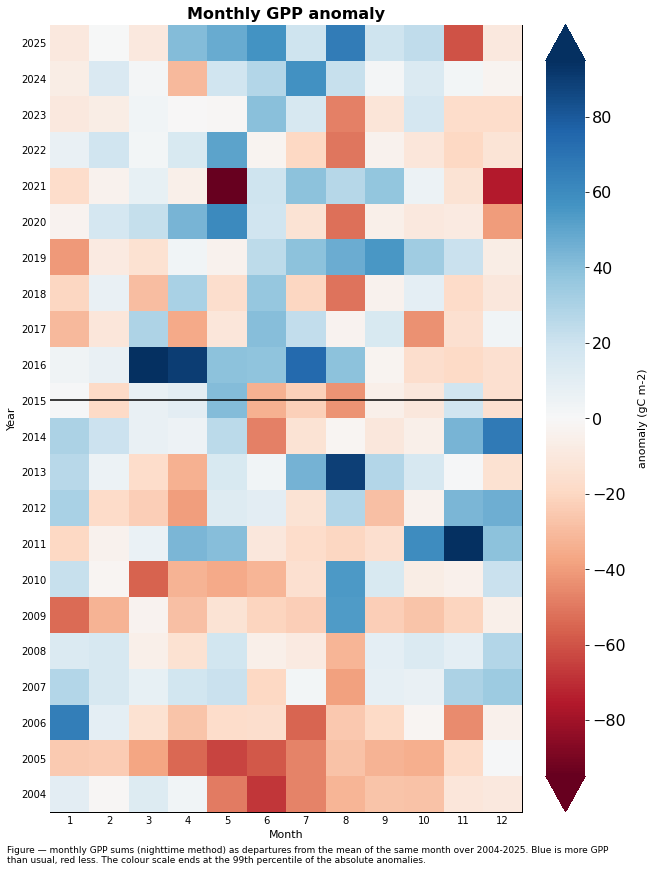

In [35]:
_anom = monthly_by_number - monthly_by_number.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()
_long = _anom.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
_absmax = _long['z'].abs().quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=ax, cmap='RdBu', vmin=-_absmax, vmax=_absmax, cb_extend='both', xlabel="Month", ylabel="Year",
    zlabel=f"anomaly ({units_sum})",
    format_style=dv.plotting.FormatStyle(title=f"Monthly {var} anomaly", axlabel_fontsize=11, ticks_fontsize=10))
ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, f"monthly GPP sums (nighttime method) as departures from the mean of the same month over "
            f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Blue is more GPP than usual, red less. The "
            f"colour scale ends at the 99th percentile of the absolute anomalies.")

</br>

# Anomalies and trends

## Per year

### 📊 Plot: yearly anomalies

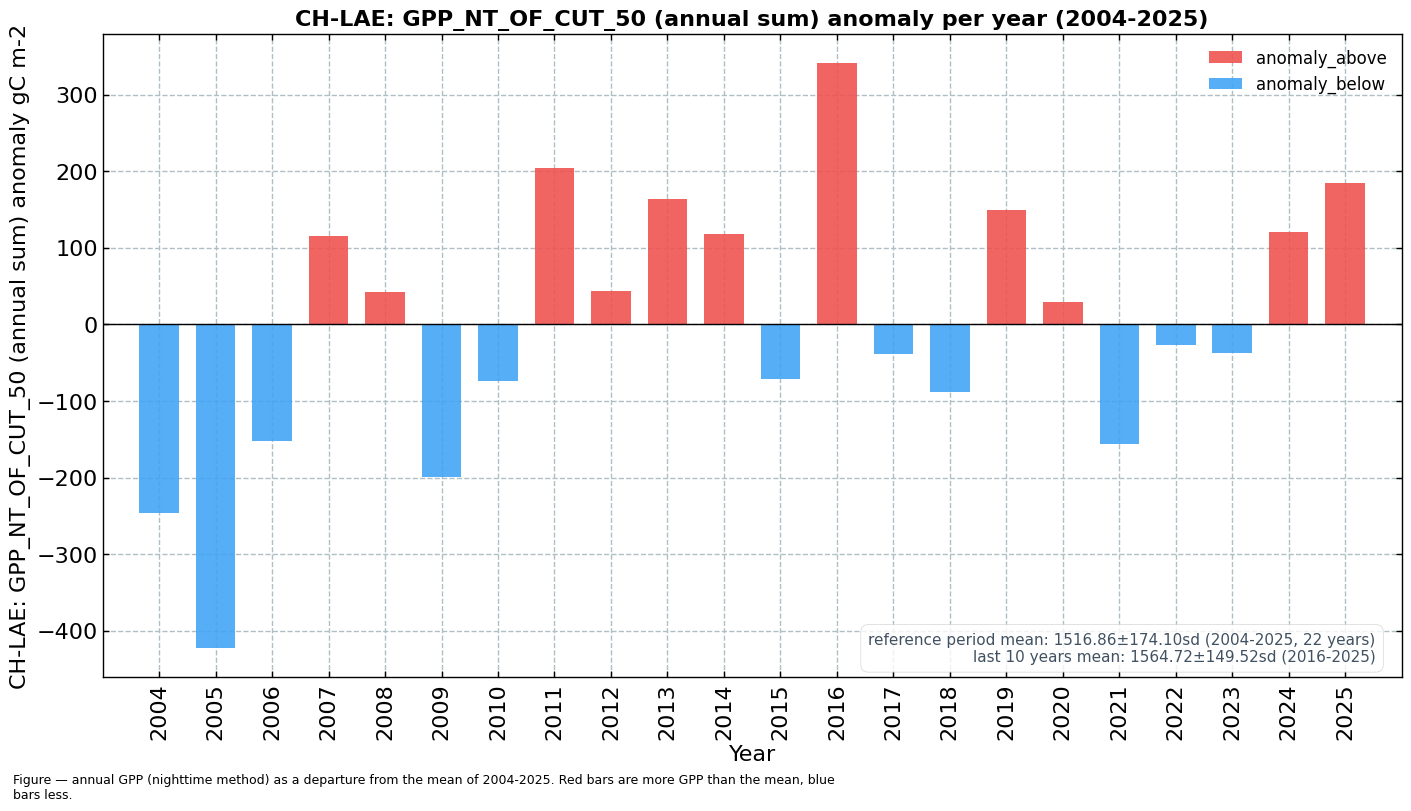

In [36]:
_anomalies_year = LongtermAnomaliesYear(series=yt.rename(varname),
                                        series_label=f"CH-LAE: {varname} (annual sum)",
                                        series_units=units_sum,
                                        reference_start_year=REFERENCE_START_YEAR,
                                        reference_end_year=REFERENCE_END_YEAR)
_anomalies_year.plot()
figcap(_anomalies_year.fig,
       f"annual GPP (nighttime method) as a departure from the mean of "
       f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Red bars are more GPP than the mean, blue bars less.")

## Trends

A trend over the whole record crosses the change of analyser. It is therefore given three ways:
over all years, over the LI-7200 years alone, and with a step at 2016 removed, so that a trend
carried by the step alone can be told apart. The same is done for the robust variant and the
daytime method.

### 📋 Table: trends of the annual sums

In [37]:
def _trend_row(s):
    _fit = trend(s.dropna())
    return {f"trend ({units_sum}/decade)": _fit['slope'], "lower 95 %": _fit['low'], "upper 95 %": _fit['high'],
            "p": _fit['pvalue'], "years": int(s.notna().sum())}


_rows = {}
for _c, _label in ((f"GPP NT ({units_sum})", "GPP NT"), ("NT robust", "GPP NT robust"), ("GPP DT", "GPP DT")):
    _s = annual[_c]
    _first = int(_s.first_valid_index())
    _rows[(_label, f"all years, {_first}-{LAST_YEAR}")] = _trend_row(_s)
    _rows[(_label, f"LI-7200 years, 2016-{LAST_YEAR}")] = _trend_row(_s.loc[2016:])
    _rows[(_label, "all years, step at 2016 removed")] = _trend_row(
        _s - annual.groupby('analyser')[_c].transform('mean') + _s.mean())
trends = pd.DataFrame.from_dict(_rows, orient='index')
trends.index.names = ['flux', 'years']
display(styled(trends, caption="Theil-Sen trends of the annual GPP sums with their 95 % interval and "
                               "Kendall p. Removing the step subtracts each analyser period's own mean, "
                               "so only the trend within the periods remains",
               fmt={c: ("{:.4f}" if c == "p" else "{:.0f}" if c == "years" else "{:+.1f}") for c in trends.columns},
               subset=[f"trend ({units_sum}/decade)"], cmap='RdBu', center=True))

Table — Theil-Sen trends of the annual GPP sums with their 95 % interval and Kendall p. Removing the
step subtracts each analyser period's own mean, so only the trend within the periods remains



### 📊 Plot: annual sums and their trends

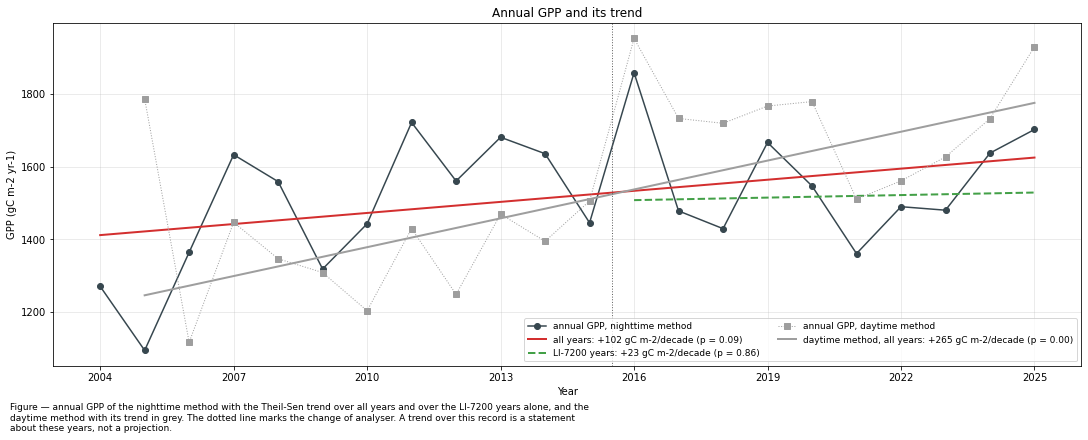

In [38]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.plot(yt.index, yt, marker='o', color='#37474F', lw=1.5, label="annual GPP, nighttime method")
_fit = trend(yt)
ax.plot(_fit['fit'].index, _fit['fit'], color='#D32F2F', lw=2,
        label=f"all years: {_fit['slope']:+.0f} {units_sum}/decade (p = {_fit['pvalue']:.2f})")
_fit72 = trend(yt.loc[2016:])
ax.plot(_fit72['fit'].index, _fit72['fit'], color='#43A047', lw=2, ls='--',
        label=f"LI-7200 years: {_fit72['slope']:+.0f} {units_sum}/decade (p = {_fit72['pvalue']:.2f})")
_ydt = annual["GPP DT"].dropna()
ax.plot(_ydt.index, _ydt, marker='s', color='#9E9E9E', lw=1, ls=':', label="annual GPP, daytime method")
_fitdt = trend(_ydt)
ax.plot(_fitdt['fit'].index, _fitdt['fit'], color='#9E9E9E', lw=2,
        label=f"daytime method, all years: {_fitdt['slope']:+.0f} {units_sum}/decade (p = {_fitdt['pvalue']:.2f})")
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xlabel("Year")
ax.set_ylabel(f"GPP ({units_sum} yr-1)")
ax.set_title("Annual GPP and its trend")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, ncol=2, loc='lower right')
year_axis(ax)
figcap(fig, "annual GPP of the nighttime method with the Theil-Sen trend over all years and over the "
            "LI-7200 years alone, and the daytime method with its trend in grey. The dotted line marks "
            "the change of analyser. A trend over this record is a statement about these years, not a "
            "projection.")
fig.show()

</br>

# Cumulative plot

## 📊 Plot: cumulative GPP per year

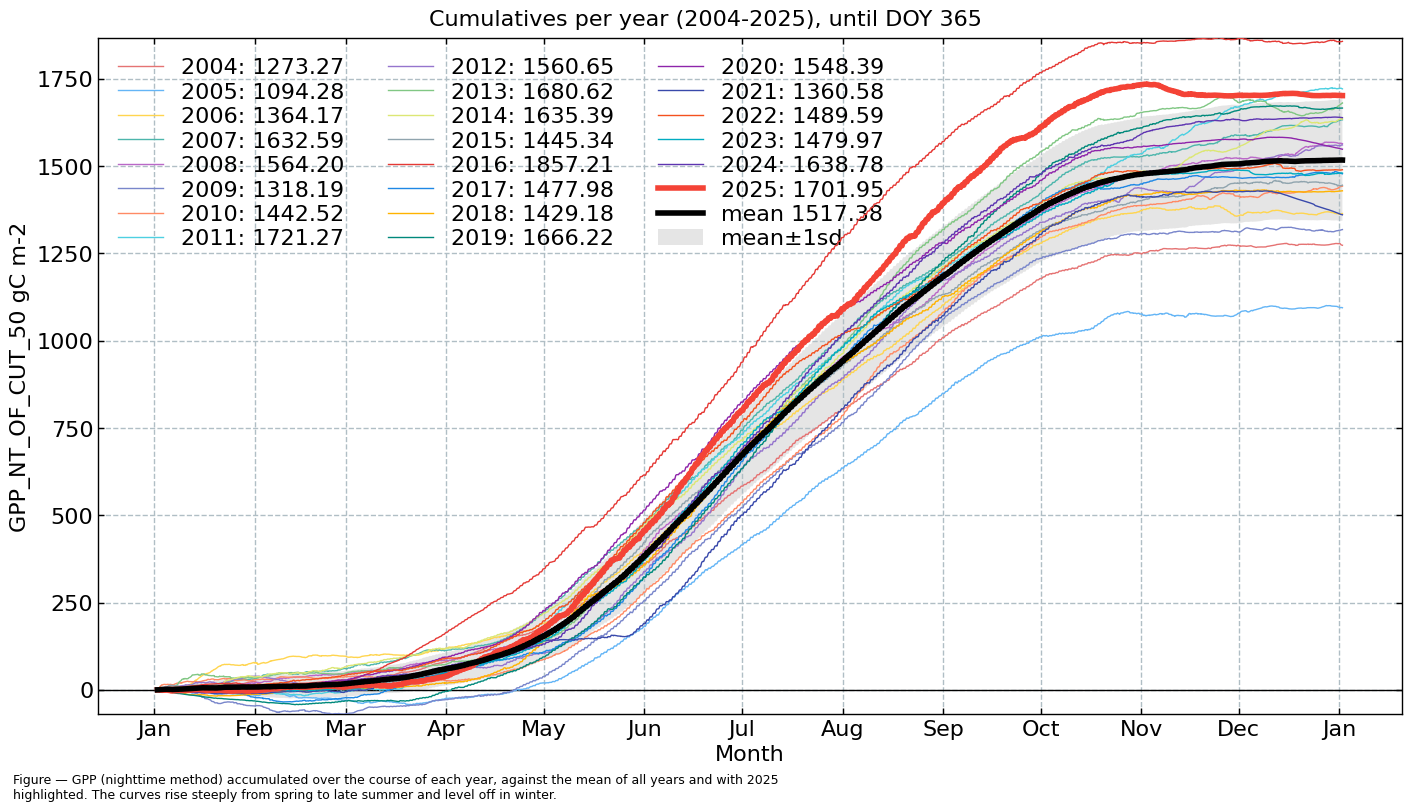

In [39]:
_cumulative = CumulativeYear(
    series=(series * UMOL_TO_GC).rename(varname),
    series_units=units_sum,
    start_year=FIRST_YEAR,
    end_year=LAST_YEAR,
    show_reference=True,
    excl_years_from_reference=None,
    highlight_year=LAST_YEAR)
_cumulative.plot(highlight_year_color='#F44336')
figcap(_cumulative.fig,
       f"GPP (nighttime method) accumulated over the course of each year, against the mean of all years "
       f"and with {LAST_YEAR} highlighted. The curves rise steeply from spring to late summer and level "
       f"off in winter.")

</br>

# Distributions

## 📊 Plot: distribution per year

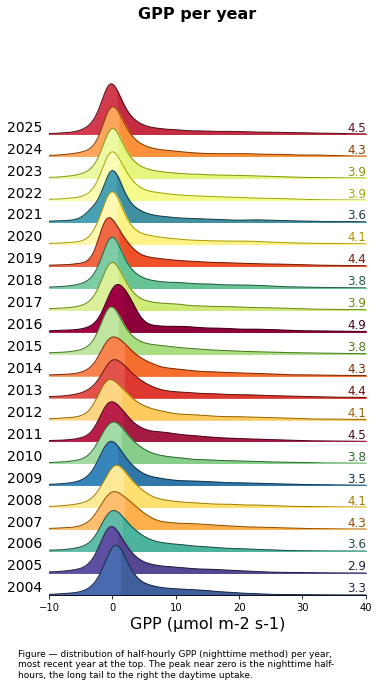

In [40]:
rp = dv.plotting.RidgeLinePlot(series=series)
rp.plot(
    how='yearly',
    kd_kwargs=None,  # params from scikit KernelDensity as dict
    xlim=[-10, 40],  # min/max as list
    ylim=[0, 0.3],  # min/max as list
    hspace=-0.8,  # overlap between years
    fig_width=5,
    fig_height=9,
    shade_percentile=0.5,
    show_mean_line=False,
    format_style=dv.plotting.FormatStyle(xlabel=xlabel, title=f"{var} per year"),
    fig_dpi=72,
    showplot=True,
    ascending=False
)
figcap(rp.fig, f"distribution of half-hourly GPP (nighttime method) per year, most recent year at the "
               f"top. The peak near zero is the nighttime half-hours, the long tail to the right the "
               f"daytime uptake.")

</br>

# End of notebook

In [41]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
_runtime = datetime.now() - NOTEBOOK_START
print(f"Finished. {dt_string}")
print(f"Runtime: {_runtime.total_seconds() / 60:.1f} minutes")

Finished. 2026-10-30 22:05:33
Runtime: 0.1 minutes
